# Jar Growth Intern Assignment: Question 1, Python Sales Data Analysis
**Candidate:** Vivek Kumar Singh

In [7]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\Lenovo\Downloads\jar assigmnent
['.dist', 'datasets', 'Jar_Sales_Analysis_Updated.ipynb', 'notbook.ipynb', 'outputs']


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

In [9]:
Orders = pd.read_csv("datasets/List_of_Orders.csv")
Details = pd.read_csv("datasets/Order_Details.csv")
Target = pd.read_csv("datasets/Sales-target.csv")

print(Orders.shape)
print(Details.shape)
print(Target.shape)

(500, 5)
(1500, 6)
(37, 4)


In [10]:
Details.head()
Orders.head()
Target.head()

,Month of Order Date,Order Date,Category,Target
0,NaN,NaN,NaN,NaN
1,Apr-18 Furniture 10400,18-Apr-26,Furniture,10400.0
2,May-18 Furniture 10500,18-May-26,Furniture,10500.0
3,Jun-18 Furniture 10600,18-Jun-26,Furniture,10600.0
4,Jul-18 Furniture 10800,18-Jul-26,Furniture,10800.0


In [25]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
FILES = {
    "orders": "List_of_Orders_-_List_of_Orders.pdf",
    "details": "Order_Details_-_Order_Details.pdf",
    "target": "Sales_target_-_Sales_target.pdf",
}
CATEGORY_COLORS = {"Clothing": "#2E86AB", "Electronics": "#F18F01", "Furniture": "#6B8E23"}

In [12]:
# Preview datasets
display(Orders.head())
display(Details.head())
display(Target.head())

,Order ID,Order Date,CustomerName,State,City
0,B-25601,1/4/2018,Bharat,Gujarat,Ahmedabad
1,B-25602,1/4/2018,Pearl,Maharashtra,Pune
2,B-25603,3/4/2018,Jahan,Madhya Pradesh,Bhopal
3,B-25604,3/4/2018,Divsha,Rajasthan,Jaipur
4,B-25605,5/4/2018,Kasheen,West Bengal,Kolkata


,Order ID,Amount,Profit,Quantity,Category,Sub-Category
0,B-25601,1275,-1148,7,Furniture,Bookcases
1,B-25601,66,-12,5,Clothing,Stole
2,B-25601,8,-2,3,Clothing,Hankerchief
3,B-25601,80,-56,4,Electronics,Electronic Games
4,B-25602,168,-111,2,Electronics,Phones


,Month of Order Date,Order Date,Category,Target
0,NaN,NaN,NaN,NaN
1,Apr-18 Furniture 10400,18-Apr-26,Furniture,"10,400.00"
2,May-18 Furniture 10500,18-May-26,Furniture,"10,500.00"
3,Jun-18 Furniture 10600,18-Jun-26,Furniture,"10,600.00"
4,Jul-18 Furniture 10800,18-Jul-26,Furniture,"10,800.00"


In [13]:
# Dataset information

datasets = {
    "Orders": Orders,
    "Details": Details,
    "Target": Target
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"{name} Dataset")
    print(f"{'=' * 50}")

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())


Orders Dataset
Shape: (500, 5)

Columns:
['Order ID', 'Order Date', 'CustomerName', 'State', 'City']

Data types:
Order ID        object
Order Date      object
CustomerName    object
State           object
City            object
dtype: object

Missing values:
Order ID        0
Order Date      0
CustomerName    0
State           0
City            0
dtype: int64

Duplicate rows: 0

Details Dataset
Shape: (1500, 6)

Columns:
['Order ID', 'Amount', 'Profit', 'Quantity', 'Category', 'Sub-Category']

Data types:
Order ID        object
Amount           int64
Profit           int64
Quantity         int64
Category        object
Sub-Category    object
dtype: object

Missing values:
Order ID        0
Amount          0
Profit          0
Quantity        0
Category        0
Sub-Category    0
dtype: int64

Duplicate rows: 0

Target Dataset
Shape: (37, 4)

Columns:
['Month of Order Date', 'Order Date', 'Category     ', ' Target']

Data types:
Month of Order Date     object
Order Date              obj

## Raw data copies

In [112]:
# keep untouched copies of the raw data before any cleaning

raw_Orders = Orders.copy()
raw_Details = Details.copy()
raw_Target = Target.copy()

os.makedirs("outputs/tables", exist_ok=True)
os.makedirs("outputs/charts", exist_ok=True)

print("Raw copies stored:", raw_Orders.shape, raw_Details.shape, raw_Target.shape)

Raw copies stored: (500, 5) (1500, 6) (37, 6)


In [111]:
# Clean column names

for df in [Orders, Details, Target]:
    df.columns = df.columns.str.strip()

for df in [Orders, Details, Target]:
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].str.strip()

print("Orders columns:", Orders.columns.tolist())
print("Details columns:", Details.columns.tolist())
print("Target columns:", Target.columns.tolist())

Orders columns: ['Order ID', 'Order Date', 'CustomerName', 'State', 'City']
Details columns: ['Order ID', 'Amount', 'Profit', 'Quantity', 'Category', 'Sub-Category']
Target columns: ['Month', 'Order Date', 'Category', 'Target', 'Month_Number', 'Year_Month']


In [16]:
display(Orders.head())
display(Details.head())
display(Target.head())

,Order ID,Order Date,CustomerName,State,City
0,B-25601,1/4/2018,Bharat,Gujarat,Ahmedabad
1,B-25602,1/4/2018,Pearl,Maharashtra,Pune
2,B-25603,3/4/2018,Jahan,Madhya Pradesh,Bhopal
3,B-25604,3/4/2018,Divsha,Rajasthan,Jaipur
4,B-25605,5/4/2018,Kasheen,West Bengal,Kolkata


,Order ID,Amount,Profit,Quantity,Category,Sub-Category
0,B-25601,1275,-1148,7,Furniture,Bookcases
1,B-25601,66,-12,5,Clothing,Stole
2,B-25601,8,-2,3,Clothing,Hankerchief
3,B-25601,80,-56,4,Electronics,Electronic Games
4,B-25602,168,-111,2,Electronics,Phones


,Month of Order Date,Order Date,Category,Target
0,NaN,NaN,NaN,NaN
1,Apr-18 Furniture 10400,18-Apr-26,Furniture,"10,400.00"
2,May-18 Furniture 10500,18-May-26,Furniture,"10,500.00"
3,Jun-18 Furniture 10600,18-Jun-26,Furniture,"10,600.00"
4,Jul-18 Furniture 10800,18-Jul-26,Furniture,"10,800.00"


In [110]:

cleaning_log = []

for name, raw, clean in [("Orders", raw_Orders, Orders), ("Details", raw_Details, Details), ("Target", raw_Target, Target)]:
    changed = 0
    for i in range(raw.shape[1]):
        if str(raw.iloc[:, i].dtype) in ["object", "str", "string"]:
            changed += int((raw.iloc[:, i].astype(str) != clean.iloc[:, i].astype(str)).sum())

    cleaning_log.append({
        "Dataset": name,
        "Check": "Whitespace in text columns",
        "Records affected": changed,
        "Action": "Trimmed" if changed > 0 else "None needed"
    })

display(pd.DataFrame(cleaning_log))

,Dataset,Check,Records affected,Action
0,Orders,Whitespace in text columns,500,Trimmed
1,Details,Whitespace in text columns,0,None needed
2,Target,Whitespace in text columns,36,Trimmed


In [18]:
# Missing values in each dataset

missing_report = pd.concat(
    {
        "Orders": Orders.isnull().sum(),
        "Details": Details.isnull().sum(),
        "Target": Target.isnull().sum()
    },
    axis=1
)

display(missing_report)

,Orders,Details,Target
Order ID,0.00,0.00,NaN
Order Date,0.00,NaN,1.00
CustomerName,0.00,NaN,NaN
State,0.00,NaN,NaN
City,0.00,NaN,NaN
Amount,NaN,0.00,NaN
Profit,NaN,0.00,NaN
Quantity,NaN,0.00,NaN
Category,NaN,0.00,1.00
Sub-Category,NaN,0.00,NaN


In [19]:
# Check duplicate records

print("Duplicate rows in Orders:", Orders.duplicated().sum())
print("Duplicate rows in Details:", Details.duplicated().sum())
print("Duplicate rows in Target:", Target.duplicated().sum())

# Check unique order IDs

print("\nUnique order IDs in Orders:", Orders["Order ID"].nunique())
print("Unique order IDs in Details:", Details["Order ID"].nunique())

# Check whether the order header table has duplicate order IDs

duplicate_order_ids = Orders[
    Orders["Order ID"].duplicated(keep=False)
].sort_values("Order ID")

display(duplicate_order_ids)

Duplicate rows in Orders: 0
Duplicate rows in Details: 0
Duplicate rows in Target: 0

Unique order IDs in Orders: 500
Unique order IDs in Details: 500


,Order ID,Order Date,CustomerName,State,City


In [20]:
# Convert order dates

Orders["Order Date"] = pd.to_datetime(
    Orders["Order Date"],
    errors="coerce",
    dayfirst=True
)

# Convert numerical columns

for col in ["Amount", "Profit", "Quantity"]:
    if col in Details.columns:
        Details[col] = pd.to_numeric(
            Details[col],
            errors="coerce"
        )

if "Target" in Target.columns:
    Target["Target"] = pd.to_numeric(
        Target["Target"],
        errors="coerce"
    )

# Check conversion results

print("Order date data type:", Orders["Order Date"].dtype)

print("\nDetails data types:")
display(Details.dtypes)

print("\nTarget data types:")
display(Target.dtypes)

Order date data type: datetime64[ns]

Details data types:


Order ID        object
Amount           int64
Profit           int64
Quantity         int64
Category        object
Sub-Category    object
dtype: object


Target data types:


Month of Order Date     object
Order Date              object
Category                object
Target                 float64
dtype: object

In [21]:
print("Invalid order dates:", Orders["Order Date"].isna().sum())

if "Amount" in Details.columns:
    print("Invalid sales values:", Details["Amount"].isna().sum())

if "Profit" in Details.columns:
    print("Invalid profit values:", Details["Profit"].isna().sum())

Invalid order dates: 307
Invalid sales values: 0
Invalid profit values: 0


In [22]:
quality_report = pd.DataFrame({
    "Dataset": ["Orders", "Details", "Target"],
    "Rows": [
        len(Orders),
        len(Details),
        len(Target)
    ],
    "Columns": [
        len(Orders.columns),
        len(Details.columns),
        len(Target.columns)
    ],
    "Missing Values": [
        Orders.isnull().sum().sum(),
        Details.isnull().sum().sum(),
        Target.isnull().sum().sum()
    ],
    "Duplicate Rows": [
        Orders.duplicated().sum(),
        Details.duplicated().sum(),
        Target.duplicated().sum()
    ]
})

display(quality_report)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Orders,500,5,307,0
1,Details,1500,6,0,0
2,Target,37,4,4,0


## Data dictionary and extra data-quality checks

In [108]:
# data dictionary based on the actual columns

meaning = {
    ("Orders", "Order ID"): "Order identifier, one row per order",
    ("Orders", "Order Date"): "Date the order was placed",
    ("Orders", "CustomerName"): "Customer first name (repeats across orders, not a unique key)",
    ("Orders", "State"): "State or territory of the order",
    ("Orders", "City"): "City of the order",
    ("Details", "Order ID"): "Links each line item to its order (repeats for multi-item orders)",
    ("Details", "Amount"): "Sales value of the line item",
    ("Details", "Profit"): "Profit of the line item (negative means a loss)",
    ("Details", "Quantity"): "Units on the line item",
    ("Details", "Category"): "Product category",
    ("Details", "Sub-Category"): "Product sub-category",
    ("Target", "Month of Order Date"): "Target month (Mon-yy)",
    ("Target", "Category"): "Category the target applies to",
    ("Target", "Target"): "Monthly sales target for the category",
}

dictionary_rows = []

for name, df in [("Orders", Orders), ("Details", Details), ("Target", Target)]:
    for col in df.columns:
        dictionary_rows.append([name, col, str(df[col].dtype), meaning.get((name, col), "")])

data_dictionary = pd.DataFrame(
    dictionary_rows,
    columns=["Dataset", "Column", "Data type", "Meaning"]
)

display(data_dictionary)

,Dataset,Column,Data type,Meaning
0,Orders,Order ID,object,"Order identifier, one row per order"
1,Orders,Order Date,datetime64[ns],Date the order was placed
2,Orders,CustomerName,object,"Customer first name (repeats across orders, no..."
3,Orders,State,object,State or territory of the order
4,Orders,City,object,City of the order
5,Details,Order ID,object,Links each line item to its order (repeats for...
6,Details,Amount,int64,Sales value of the line item
7,Details,Profit,int64,Profit of the line item (negative means a loss)
8,Details,Quantity,int64,Units on the line item
9,Details,Category,object,Product category


In [113]:
# check the order ID format in both order tables

id_pattern = r"^B-\d{5}$"

bad_ids = (
    (~Orders["Order ID"].astype(str).str.match(id_pattern)).sum()
    + (~Details["Order ID"].astype(str).str.match(id_pattern)).sum()
)

print("Malformed order IDs:", bad_ids)

cleaning_log.append({
    "Dataset": "Orders and Details",
    "Check": "Malformed order IDs",
    "Records affected": int(bad_ids),
    "Action": "None needed" if bad_ids == 0 else "Investigate"
})

# Check label consistency

print("\nCategories in Details:", sorted(Details["Category"].dropna().unique()))
print("Categories in Target:", sorted(Target["Category"].dropna().unique()))
print("Sub-categories:", sorted(Details["Sub-Category"].dropna().unique()))
print("States:", sorted(Orders["State"].dropna().unique()))
print("Cities:", sorted(Orders["City"].dropna().unique()))

# Check for labels that differ only by upper or lower case

for df_name, df, col in [
    ("Details", Details, "Category"),
    ("Details", Details, "Sub-Category"),
    ("Orders", Orders, "State"),
    ("Orders", Orders, "City")
]:
    print(
        df_name, col, "->",
        df[col].nunique(), "labels,",
        df[col].str.lower().nunique(), "labels after lowercasing"
    )

# Check that every Details category has a target

print("\nCategories without targets:", set(Details["Category"]) - set(Target["Category"]))

Malformed order IDs: 0

Categories in Details: ['Clothing', 'Electronics', 'Furniture']
Categories in Target: ['Clothing', 'Electronics', 'Furniture']
Sub-categories: ['Accessories', 'Bookcases', 'Chairs', 'Electronic Games', 'Furnishings', 'Hankerchief', 'Kurti', 'Leggings', 'Phones', 'Printers', 'Saree', 'Shirt', 'Skirt', 'Stole', 'T-shirt', 'Tables', 'Trousers']
States: ['Andhra Pradesh', 'Bihar', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Nagaland', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Uttar Pradesh', 'West Bengal']
Cities: ['Ahmedabad', 'Allahabad', 'Amritsar', 'Bangalore', 'Bhopal', 'Chandigarh', 'Chennai', 'Delhi', 'Gangtok', 'Goa', 'Hyderabad', 'Indore', 'Jaipur', 'Kashmir', 'Kohima', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Pune', 'Simla', 'Surat', 'Thiruvananthapuram', 'Udaipur']
Details Category -> 3 labels, 3 labels after lowercasing
Details Sub-Category -> 17 labels, 17

In [114]:
# check unexpected numeric values

nonpositive_amount = int((Details["Amount"] <= 0).sum())
nonpositive_quantity = int((Details["Quantity"] <= 0).sum())
negative_profit_lines = int((Details["Profit"] < 0).sum())
zero_profit_lines = int((Details["Profit"] == 0).sum())
loss_exceeds_sales = int((Details["Profit"] < -Details["Amount"]).sum())
profit_above_sales = int((Details["Profit"] > Details["Amount"]).sum())

print("Lines with Amount <= 0:", nonpositive_amount)
print("Lines with Quantity <= 0:", nonpositive_quantity)
print("Lines with negative profit:", negative_profit_lines)
print("Lines with zero profit:", zero_profit_lines)
print("Lines where the loss is larger than the sales amount:", loss_exceeds_sales)
print("Lines where profit is larger than the sales amount:", profit_above_sales)

for check, count, action in [
    ("Amount or Quantity <= 0", nonpositive_amount + nonpositive_quantity, "None needed"),
    ("Negative profit lines", negative_profit_lines, "Preserved (real losses)"),
    ("Loss larger than line sales", loss_exceeds_sales, "Preserved and flagged"),
    ("Profit larger than line sales", profit_above_sales, "None needed")
]:
    cleaning_log.append({
        "Dataset": "Details",
        "Check": check,
        "Records affected": count,
        "Action": action
    })

# Lines where the loss is larger than the sales amount (kept, flagged)

display(
    Details[Details["Profit"] < -Details["Amount"]]
    .sort_values("Profit")
    .head(15)
)

Lines with Amount <= 0: 0
Lines with Quantity <= 0: 0
Lines with negative profit: 503
Lines with zero profit: 47
Lines where the loss is larger than the sales amount: 14
Lines where profit is larger than the sales amount: 0


,Order ID,Amount,Profit,Quantity,Category,Sub-Category
22,B-25608,1364,-1864,5,Furniture,Tables
249,B-25686,332,-503,3,Electronics,Printers
466,B-25756,204,-276,3,Furniture,Bookcases
335,B-25712,193,-275,3,Electronics,Phones
1140,B-25983,161,-229,8,Furniture,Furnishings
1039,B-25953,188,-193,2,Electronics,Electronic Games
374,B-25731,131,-154,8,Furniture,Furnishings
441,B-25753,47,-114,5,Furniture,Furnishings
100,B-25644,76,-92,8,Furniture,Furnishings
559,B-25789,67,-86,9,Furniture,Furnishings


In [115]:
# check the date range and the target table

print("Order date range:", Orders["Order Date"].min().date(), "to", Orders["Order Date"].max().date())

orders_per_month = (
    Orders.groupby(Orders["Order Date"].dt.to_period("M"))
    .size()
    .rename("Orders")
    .to_frame()
)

display(orders_per_month)

duplicate_targets = Target.duplicated(subset=["Month of Order Date", "Category"]).sum()
print("Duplicate month and category rows in Target:", duplicate_targets)

cleaning_log.append({
    "Dataset": "Target",
    "Check": "Duplicate month and category rows",
    "Records affected": int(duplicate_targets),
    "Action": "None needed" if duplicate_targets == 0 else "Investigate"
})

Order date range: 2018-04-01 to 2019-03-12


,Orders
Order Date,
2018-04,13
2018-05,12
2018-06,13
2018-07,14
2018-08,12
2018-09,12
2018-10,19
2018-11,17
2018-12,22


KeyError: Index(['Month of Order Date'], dtype='object')

In [116]:
# flag unusually large line items using the IQR rule (flagged only, not removed)

q1 = Details["Amount"].quantile(0.25)
q3 = Details["Amount"].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)

amount_outliers = Details[Details["Amount"] > upper_limit]

print("Upper limit for Amount:", round(upper_limit, 2))
print("Large line items:", len(amount_outliers))
print(f"Share of total sales: {amount_outliers['Amount'].sum() / Details['Amount'].sum() * 100:.1f}%")

display(amount_outliers.sort_values("Amount", ascending=False).head(10))

cleaning_log.append({
    "Dataset": "Details",
    "Check": "Large Amount values (IQR rule)",
    "Records affected": len(amount_outliers),
    "Action": "Kept and flagged (large purchases are plausible)"
})

cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)

Upper limit for Amount: 737.5
Large line items: 155
Share of total sales: 48.7%


,Order ID,Amount,Profit,Quantity,Category,Sub-Category
1356,B-26055,5729,64,14,Furniture,Chairs
1167,B-25993,4363,305,5,Furniture,Tables
1116,B-25973,4141,1698,13,Electronics,Printers
956,B-25923,3873,891,6,Electronics,Phones
472,B-25757,3151,-35,7,Clothing,Trousers
1061,B-25955,2927,146,8,Furniture,Bookcases
1466,B-26093,2847,712,8,Electronics,Printers
589,B-25798,2830,-1981,13,Furniture,Bookcases
6,B-25602,2617,1151,4,Electronics,Phones
780,B-25858,2457,665,11,Electronics,Electronic Games


,Dataset,Check,Records affected,Action
0,Orders,Whitespace in text columns,500,Trimmed
1,Details,Whitespace in text columns,0,None needed
2,Target,Whitespace in text columns,36,Trimmed
3,Orders and Details,Malformed order IDs,0,None needed
4,Details,Amount or Quantity <= 0,0,None needed
5,Details,Negative profit lines,503,Preserved (real losses)
6,Details,Loss larger than line sales,14,Preserved and flagged
7,Details,Profit larger than line sales,0,None needed
8,Details,Large Amount values (IQR rule),155,Kept and flagged (large purchases are plausible)


In [30]:
# Order IDs present in each dataset

orders_ids = set(Orders["Order ID"].dropna())
details_ids = set(Details["Order ID"].dropna())

matched_ids = orders_ids.intersection(details_ids)
unmatched_ids = details_ids - orders_ids

print("Order IDs in Orders:", len(orders_ids))
print("Order IDs in Details:", len(details_ids))
print("Matching order IDs:", len(matched_ids))
print("Unmatched order IDs in Details:", len(unmatched_ids))

Order IDs in Orders: 500
Order IDs in Details: 500
Matching order IDs: 500
Unmatched order IDs in Details: 0


In [31]:
unmatched_details = Details[
    ~Details["Order ID"].isin(orders_ids)
]

display(unmatched_details.head(10))

,Order ID,Amount,Profit,Quantity,Category,Sub-Category


In [32]:
# Check that the order header table has one record per order

if Orders["Order ID"].duplicated().any():
    raise ValueError(
        "Orders contains duplicate Order IDs. "
        "Investigate them before performing a many-to-one merge."
    )

# Merge order headers with order details

Sales = Details.merge(
    Orders,
    on="Order ID",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Merged dataset shape:", Sales.shape)

print("\nMerge results:")
display(Sales["_merge"].value_counts())

# Remove the merge indicator after validation

Sales.drop(columns="_merge", inplace=True)

display(Sales.head())

Merged dataset shape: (1500, 11)

Merge results:


_merge
both          1500
left_only        0
right_only       0
Name: count, dtype: int64

,Order ID,Amount,Profit,Quantity,Category,Sub-Category,Order Date,CustomerName,State,City
0,B-25601,1275,-1148,7,Furniture,Bookcases,2018-04-01,Bharat,Gujarat,Ahmedabad
1,B-25601,66,-12,5,Clothing,Stole,2018-04-01,Bharat,Gujarat,Ahmedabad
2,B-25601,8,-2,3,Clothing,Hankerchief,2018-04-01,Bharat,Gujarat,Ahmedabad
3,B-25601,80,-56,4,Electronics,Electronic Games,2018-04-01,Bharat,Gujarat,Ahmedabad
4,B-25602,168,-111,2,Electronics,Phones,2018-04-01,Pearl,Maharashtra,Pune


In [33]:
Sales["Year"] = Sales["Order Date"].dt.year
Sales["Month"] = Sales["Order Date"].dt.strftime("%B")
Sales["Month_Number"] = Sales["Order Date"].dt.month

# Check the extracted date information

display(
    Sales[
        ["Order Date", "Year", "Month", "Month_Number"]
    ].head()
)

,Order Date,Year,Month,Month_Number
0,2018-04-01,"2,018.00",April,4.00
1,2018-04-01,"2,018.00",April,4.00
2,2018-04-01,"2,018.00",April,4.00
3,2018-04-01,"2,018.00",April,4.00
4,2018-04-01,"2,018.00",April,4.00


In [117]:
# validate the merge (row counts, totals and multi-line orders)

print("Rows in Details:", len(Details))
print("Rows after merge:", len(Sales))
print("Amount before / after:", Details["Amount"].sum(), "/", Sales["Amount"].sum())
print("Profit before / after:", Details["Profit"].sum(), "/", Sales["Profit"].sum())
print("Unique orders in Orders / Sales:", Orders["Order ID"].nunique(), "/", Sales["Order ID"].nunique())
print("Orders with no detail lines:", len(set(Orders["Order ID"]) - set(Details["Order ID"])))

assert len(Sales) == len(Details)
assert np.isclose(Sales["Amount"].sum(), Details["Amount"].sum())
assert np.isclose(Sales["Profit"].sum(), Details["Profit"].sum())

lines_per_order = Sales.groupby("Order ID").size()

print("\nOrders with more than one line item:", (lines_per_order > 1).sum())
display(lines_per_order.describe().round(2).to_frame("Lines per order"))

# Look at one multi-line order to confirm the lines were kept

display(Sales[Sales["Order ID"] == lines_per_order.idxmax()][["Order ID", "Amount", "Profit", "Quantity", "Category", "Sub-Category", "City"]])

cleaning_log.append({
    "Dataset": "Orders and Details",
    "Check": "Merge: rows, Amount and Profit totals preserved",
    "Records affected": 0,
    "Action": "Validated (many-to-one, 0 unmatched)"
})

Rows in Details: 1500
Rows after merge: 1500
Amount before / after: 431502 / 431502
Profit before / after: 23955 / 23955
Unique orders in Orders / Sales: 500 / 500
Orders with no detail lines: 0

Orders with more than one line item: 265


,Lines per order
count,500.00
mean,3.00
std,2.48
min,1.00
25%,1.00
50%,2.00
75%,4.00
max,12.00


,Order ID,Amount,Profit,Quantity,Category,Sub-Category,City
164,B-25656,534,0,3,Clothing,Saree,Pune
165,B-25656,30,-5,5,Clothing,Stole,Pune
166,B-25656,61,-23,2,Clothing,Saree,Pune
167,B-25656,6,3,1,Clothing,Hankerchief,Pune
168,B-25656,24,-1,2,Clothing,Hankerchief,Pune
169,B-25656,56,18,2,Clothing,Hankerchief,Pune
170,B-25656,406,126,2,Clothing,Saree,Pune
171,B-25656,624,37,2,Electronics,Electronic Games,Pune
172,B-25656,101,18,9,Clothing,Skirt,Pune
173,B-25656,1389,680,7,Clothing,Saree,Pune


In [35]:
total_sales = Sales["Amount"].sum()
total_profit = Sales["Profit"].sum()
total_quantity = Sales["Quantity"].sum()
total_orders = Sales["Order ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

average_order_value = (
    total_sales / total_orders
    if total_orders != 0 else 0
)

overall_kpis = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Quantity Sold",
        "Total Orders",
        "Average Order Value",
        "Profit Margin"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_quantity,
        total_orders,
        average_order_value,
        profit_margin
    ]
})

display(overall_kpis)

,Metric,Value
0,Total Sales,"431,502.00"
1,Total Profit,"23,955.00"
2,Total Quantity Sold,"5,615.00"
3,Total Orders,500.00
4,Average Order Value,863.00
5,Profit Margin,5.55


In [36]:
print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,.0f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

Total Sales: ₹431,502.00
Total Profit: ₹23,955.00
Total Quantity Sold: 5,615
Total Orders: 500
Average Order Value: ₹863.00
Profit Margin: 5.55%


In [118]:
# extended KPIs (line items, profit per order, loss-making lines)
# Note: the source files do not state a currency, so amounts are shown without a symbol here

total_lines = len(Sales)
average_profit_per_order = total_profit / total_orders
loss_making_lines = int((Sales["Profit"] < 0).sum())

extended_kpis = pd.DataFrame({
    "Metric": [
        "Line items (detail rows)",
        "Unique orders",
        "Average sales per order",
        "Average profit per order",
        "Average lines per order",
        "Loss-making lines",
        "Loss-making lines (% of lines)",
        "Overall profit margin (%)"
    ],
    "Value": [
        total_lines,
        total_orders,
        total_sales / total_orders,
        average_profit_per_order,
        total_lines / total_orders,
        loss_making_lines,
        loss_making_lines / total_lines * 100,
        profit_margin
    ],
    "Denominator used": [
        "-", "-", "unique orders", "unique orders", "unique orders", "-", "all lines", "total sales"
    ]
})

display(extended_kpis.round(2))

,Metric,Value,Denominator used
0,Line items (detail rows),"1,500.00",-
1,Unique orders,500.00,-
2,Average sales per order,863.00,unique orders
3,Average profit per order,47.91,unique orders
4,Average lines per order,3.00,unique orders
5,Loss-making lines,503.00,-
6,Loss-making lines (% of lines),33.53,all lines
7,Overall profit margin (%),5.55,total sales


In [38]:
category_analysis = (
    Sales.groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"].replace(0, np.nan)
    * 100
)

category_analysis = category_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

display(category_analysis.round(2))

,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
1,Electronics,165267,10494,1154,204,6.35
0,Clothing,139054,11163,3516,393,8.03
2,Furniture,127181,2298,945,186,1.81


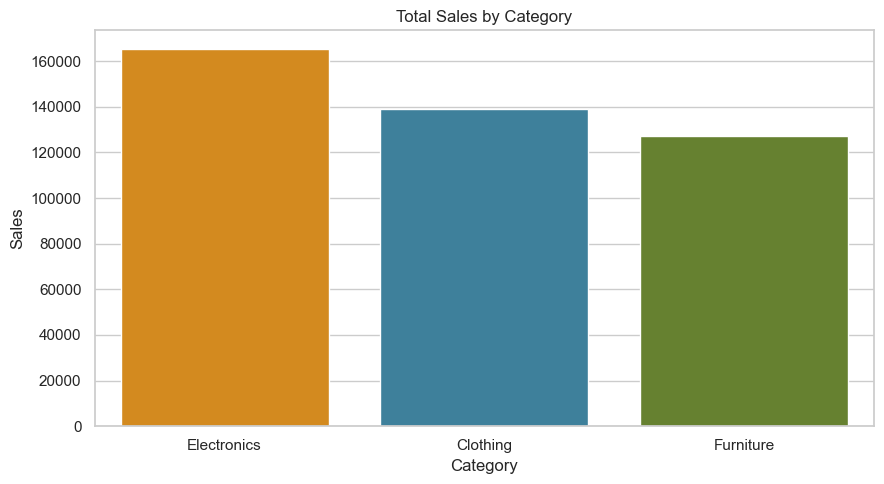

In [39]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales",
    hue="Category",
    palette=CATEGORY_COLORS,
    legend=False
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.savefig("outputs/charts/orig_category_sales.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

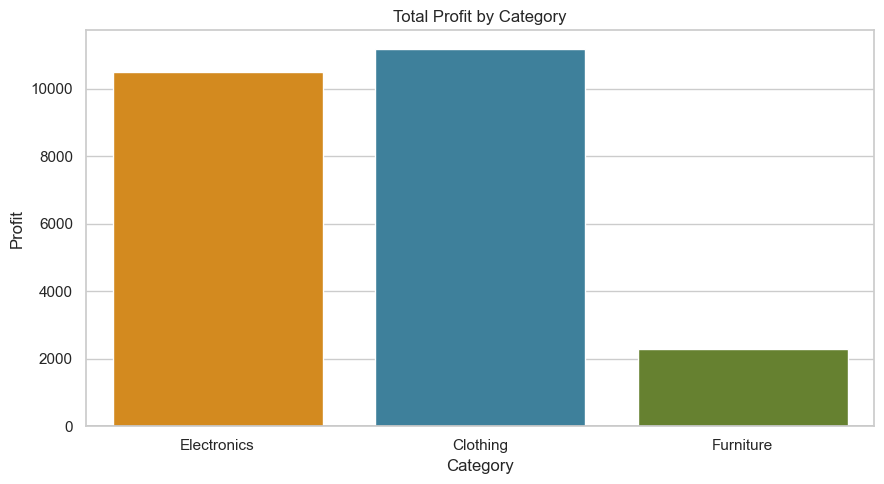

In [40]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Profit",
    hue="Category",
    palette=CATEGORY_COLORS,
    legend=False
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.tight_layout()
plt.savefig("outputs/charts/orig_category_profit.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

## Category analysis: extended

In [120]:
# extended category table (orders, profit per order, margin and contribution)
# Note: an order can contain several categories, so category order counts add up to more than the total

category_extended = (
    Sales.groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Line_Items=("Order ID", "size"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
)

category_extended["Avg_Profit_Per_Order"] = category_extended["Total_Profit"] / category_extended["Total_Orders"]
category_extended["Profit_Margin"] = category_extended["Total_Profit"] / category_extended["Total_Sales"] * 100
category_extended["Sales_Share"] = category_extended["Total_Sales"] / total_sales * 100
category_extended["Profit_Share"] = category_extended["Total_Profit"] / total_profit * 100

category_extended = category_extended.sort_values("Total_Sales", ascending=False)
display(category_extended.round(2))

top_sales_cat = category_extended.loc[category_extended["Total_Sales"].idxmax(), "Category"]
top_profit_cat = category_extended.loc[category_extended["Total_Profit"].idxmax(), "Category"]
top_margin_cat = category_extended.loc[category_extended["Profit_Margin"].idxmax(), "Category"]

print("Highest sales:", top_sales_cat)
print("Highest profit:", top_profit_cat)
print("Best margin:", top_margin_cat)

,Category,Total_Sales,Total_Profit,Line_Items,Total_Orders,Total_Quantity,Avg_Profit_Per_Order,Profit_Margin,Sales_Share,Profit_Share
1,Electronics,165267,10494,308,204,1154,51.44,6.35,38.30,43.81
0,Clothing,139054,11163,949,393,3516,28.40,8.03,32.23,46.60
2,Furniture,127181,2298,243,186,945,12.35,1.81,29.47,9.59


Highest sales: Electronics
Highest profit: Clothing
Best margin: Clothing


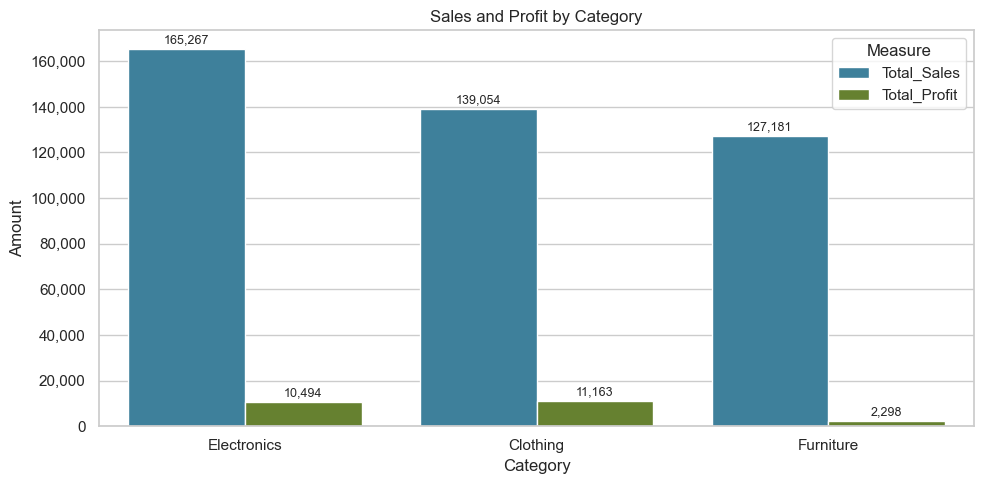

In [121]:
# sales and profit side by side, with values

plot_data = category_extended.melt(
    id_vars="Category",
    value_vars=["Total_Sales", "Total_Profit"],
    var_name="Measure",
    value_name="Value"
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plot_data,
    x="Category",
    y="Value",
    hue="Measure",
    palette=["#2E86AB", "#6B8E23"]
)

for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:,.0f}" for v in container.datavalues], fontsize=9, padding=2)

ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.tight_layout()
plt.savefig("outputs/charts/category_sales_vs_profit.png", dpi=300, bbox_inches="tight")
plt.show()

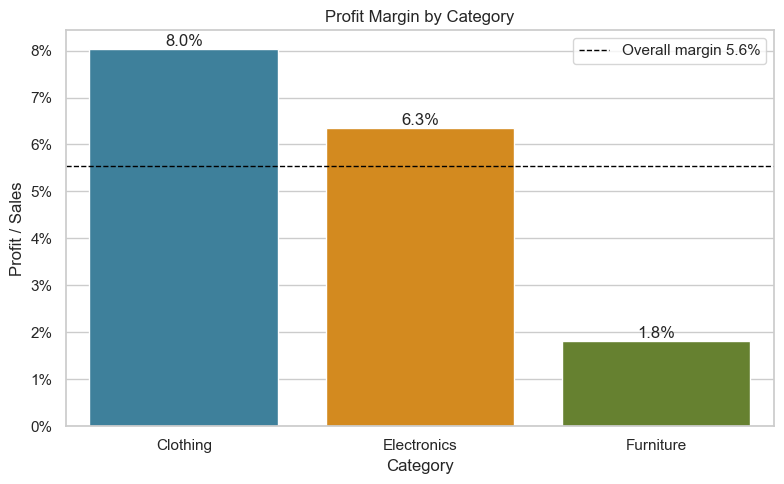

In [122]:
# profit margin by category compared with the overall margin

margin_plot = category_extended.sort_values("Profit_Margin", ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=margin_plot,
    x="Category",
    y="Profit_Margin",
    hue="Category",
    palette=CATEGORY_COLORS,
    legend=False
)

plt.axhline(profit_margin, color="black", linestyle="--", linewidth=1, label=f"Overall margin {profit_margin:.1f}%")

for i, value in enumerate(margin_plot["Profit_Margin"]):
    plt.text(i, value, f"{value:.1f}%", ha="center", va="bottom")

plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.title("Profit Margin by Category")
plt.xlabel("Category")
plt.ylabel("Profit / Sales")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/charts/category_profit_margin.png", dpi=300, bbox_inches="tight")
plt.show()

**Reading the category charts:** compare each category's share of sales with its share of profit. A category whose profit share is far below its sales share is selling a lot but earning little per unit of sales.

In [44]:
subcategory_analysis = (
    Sales.groupby(
        ["Category", "Sub-Category"],
        as_index=False
    )
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"].replace(0, np.nan)
    * 100
)

subcategory_analysis = subcategory_analysis.sort_values(
    "Total_Profit",
    ascending=True
)

display(subcategory_analysis.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
16,Furniture,Tables,22614,-4011,61,16,-17.74
10,Electronics,Electronic Games,39168,-1236,297,73,-3.16
1,Clothing,Kurti,3361,181,164,41,5.39
5,Clothing,Skirt,1946,235,248,56,12.08
2,Clothing,Leggings,2106,260,186,49,12.35
3,Clothing,Saree,53511,352,782,156,0.66
14,Furniture,Chairs,34222,577,277,64,1.69
15,Furniture,Furnishings,13484,844,310,66,6.26
4,Clothing,Shirt,7555,1131,271,66,14.97
7,Clothing,T-shirt,7382,1500,305,70,20.32


In [45]:
print("Top 5 subcategories by profit")

display(
    subcategory_analysis
    .sort_values("Total_Profit", ascending=False)
    .head(5)
)

print("Bottom 5 subcategories by profit")

display(
    subcategory_analysis
    .sort_values("Total_Profit", ascending=True)
    .head(5)
)

Top 5 subcategories by profit


,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
12,Electronics,Printers,58252,5964,291,67,10.24
13,Furniture,Bookcases,56861,4888,297,72,8.60
9,Electronics,Accessories,21728,3559,262,65,16.38
8,Clothing,Trousers,30039,2847,135,37,9.48
6,Clothing,Stole,18546,2559,671,157,13.80


Bottom 5 subcategories by profit


,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
16,Furniture,Tables,22614,-4011,61,16,-17.74
10,Electronics,Electronic Games,39168,-1236,297,73,-3.16
1,Clothing,Kurti,3361,181,164,41,5.39
5,Clothing,Skirt,1946,235,248,56,12.08
2,Clothing,Leggings,2106,260,186,49,12.35


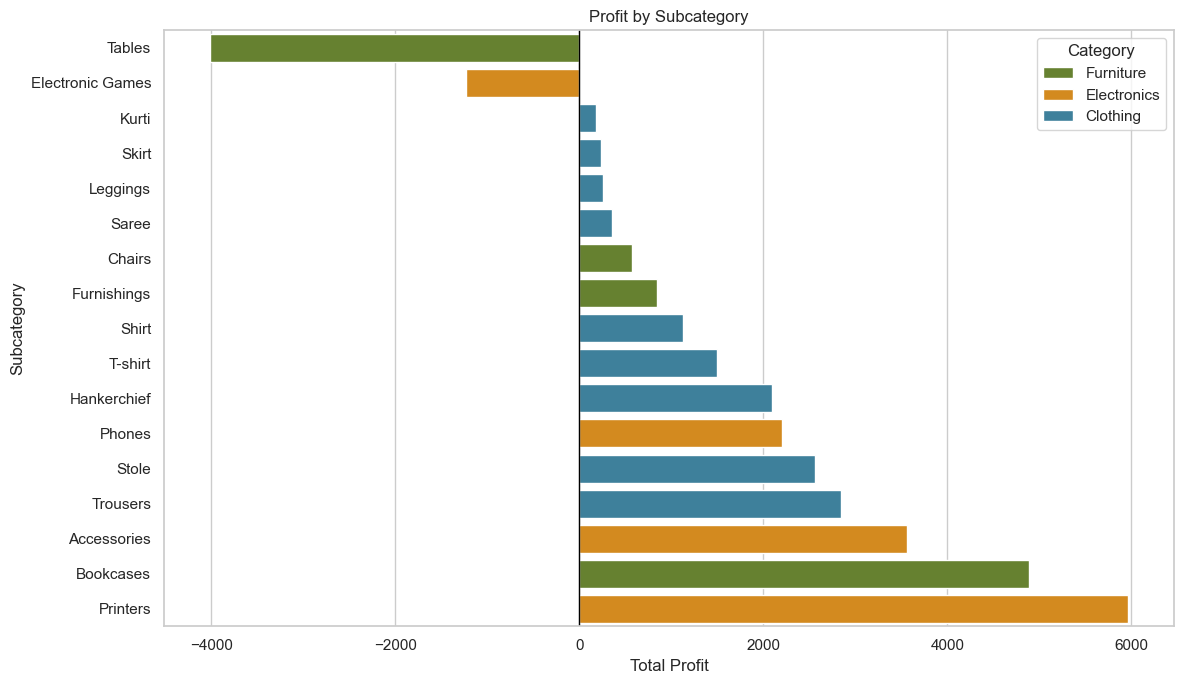

In [46]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=subcategory_analysis,
    x="Total_Profit",
    y="Sub-Category",
    hue="Category",
    dodge=False,
    palette=CATEGORY_COLORS
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Profit by Subcategory")
plt.xlabel("Total Profit")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.savefig("outputs/charts/orig_subcategory_profit.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

## Sub-category and loss-making line analysis

In [123]:
# loss-making sub-categories and high-sales / low-margin sub-categories

loss_subcategories = subcategory_analysis[subcategory_analysis["Total_Profit"] < 0]
print("Sub-categories with negative total profit:")
display(loss_subcategories.round(2))

sales_cutoff = subcategory_analysis["Total_Sales"].median()

weak_margin = subcategory_analysis[
    (subcategory_analysis["Total_Sales"] >= sales_cutoff)
    & (subcategory_analysis["Profit_Margin"] < profit_margin)
].sort_values("Total_Sales", ascending=False)

print("High-sales sub-categories with a margin below the overall margin:")
display(weak_margin.round(2))

Sub-categories with negative total profit:


,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
16,Furniture,Tables,22614,-4011,61,16,-17.74
10,Electronics,Electronic Games,39168,-1236,297,73,-3.16


High-sales sub-categories with a margin below the overall margin:


,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
3,Clothing,Saree,53511,352,782,156,0.66
11,Electronics,Phones,46119,2207,304,71,4.79
10,Electronics,Electronic Games,39168,-1236,297,73,-3.16
14,Furniture,Chairs,34222,577,277,64,1.69
16,Furniture,Tables,22614,-4011,61,16,-17.74


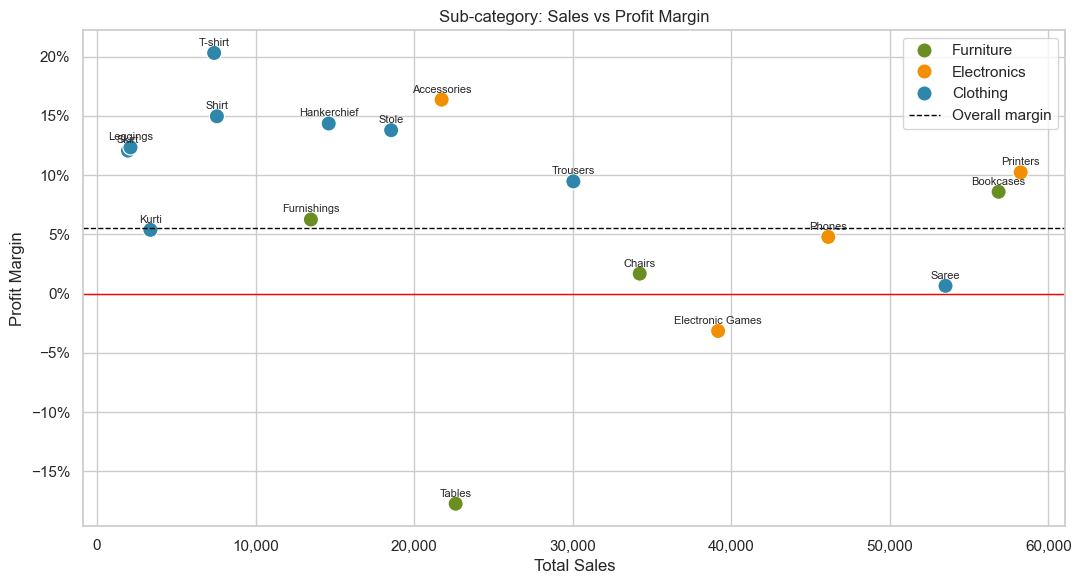

In [124]:
# sales against margin for every sub-category

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=subcategory_analysis,
    x="Total_Sales",
    y="Profit_Margin",
    hue="Category",
    palette=CATEGORY_COLORS,
    s=120
)

for _, row in subcategory_analysis.iterrows():
    plt.text(row["Total_Sales"], row["Profit_Margin"] + 0.6, row["Sub-Category"], fontsize=8, ha="center")

plt.axhline(profit_margin, color="black", linestyle="--", linewidth=1, label="Overall margin")
plt.axhline(0, color="red", linewidth=1)
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.title("Sub-category: Sales vs Profit Margin")
plt.xlabel("Total Sales")
plt.ylabel("Profit Margin")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/charts/subcategory_sales_vs_margin.png", dpi=300, bbox_inches="tight")
plt.show()

,Category,Sub-Category,Lines,Loss_Lines,Total_Loss,Loss_Line_Percent
3,Clothing,Saree,210,98,-7034,46.67
10,Electronics,Electronic Games,79,40,-5571,50.63
11,Electronics,Phones,83,41,-5481,49.40
13,Furniture,Bookcases,79,22,-5322,27.85
16,Furniture,Tables,17,11,-5187,64.71
12,Electronics,Printers,74,25,-4363,33.78
14,Furniture,Chairs,74,39,-3504,52.70
15,Furniture,Furnishings,73,30,-1508,41.10
8,Clothing,Trousers,39,15,-1401,38.46
9,Electronics,Accessories,72,16,-1307,22.22


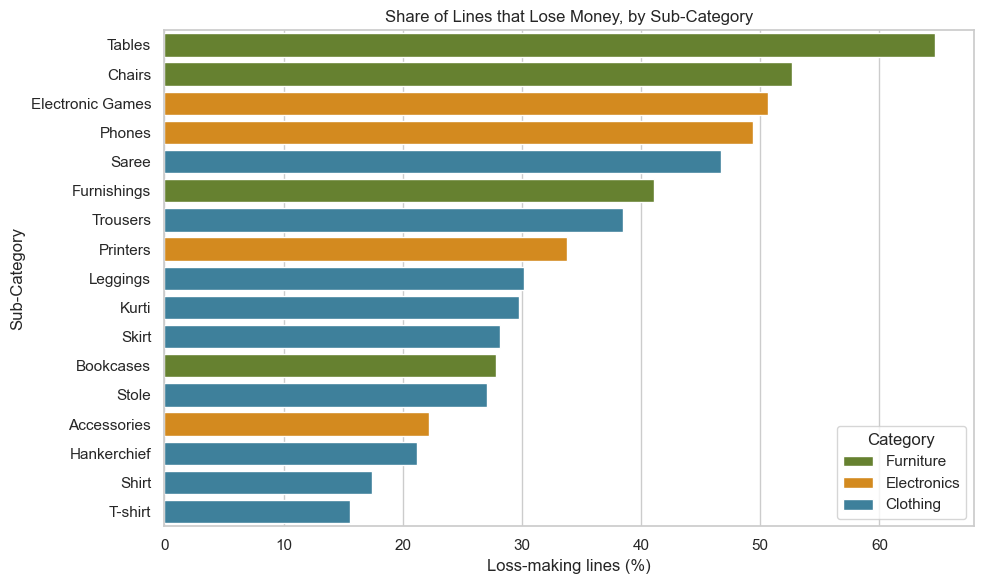

In [125]:
# how many lines lose money in each sub-category?

Sales["Is_Loss"] = Sales["Profit"] < 0

loss_by_subcategory = (
    Sales.groupby(["Category", "Sub-Category"])
    .agg(
        Lines=("Order ID", "size"),
        Loss_Lines=("Is_Loss", "sum"),
        Total_Loss=("Profit", lambda s: s[s < 0].sum())
    )
    .reset_index()
)

loss_by_subcategory["Loss_Line_Percent"] = loss_by_subcategory["Loss_Lines"] / loss_by_subcategory["Lines"] * 100
loss_by_subcategory = loss_by_subcategory.sort_values("Total_Loss")

display(loss_by_subcategory.round(2))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=loss_by_subcategory.sort_values("Loss_Line_Percent", ascending=False),
    x="Loss_Line_Percent",
    y="Sub-Category",
    hue="Category",
    dodge=False,
    palette=CATEGORY_COLORS
)

plt.title("Share of Lines that Lose Money, by Sub-Category")
plt.xlabel("Loss-making lines (%)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig("outputs/charts/loss_line_share_by_subcategory.png", dpi=300, bbox_inches="tight")
plt.show()

In [50]:
monthly_analysis = (
    Sales.groupby(
        ["Year", "Month_Number", "Month"],
        as_index=False
    )
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .sort_values(["Year", "Month_Number"])
)

display(monthly_analysis.round(2))

,Year,Month_Number,Month,Total_Sales,Total_Profit,Total_Orders
0,"2,018.00",4.00,April,15367,-2674,13
1,"2,018.00",5.00,May,16952,-1727,12
2,"2,018.00",6.00,June,12938,-1838,13
3,"2,018.00",7.00,July,5039,-210,14
4,"2,018.00",8.00,August,5961,-571,12
5,"2,018.00",9.00,September,11279,-2226,12
6,"2,018.00",10.00,October,14407,-942,19
7,"2,018.00",11.00,November,22525,6102,17
8,"2,018.00",12.00,December,19604,3247,22
9,"2,019.00",1.00,January,12380,1429,19


## Monthly analysis, fixed (replaces the two original monthly charts)

In [126]:
# the data runs from April 2018 to March 2019, so months are shown on one chronological axis
# (the original charts split the year into two disconnected lines by calendar year)

Sales["Year_Month"] = Sales["Order Date"].dt.to_period("M")

monthly_ym = (
    Sales.groupby("Year_Month")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values("Year_Month")
)

monthly_ym["Profit_Margin"] = monthly_ym["Total_Profit"] / monthly_ym["Total_Sales"].replace(0, np.nan) * 100
monthly_ym["Sales_MoM_Percent"] = monthly_ym["Total_Sales"].pct_change() * 100
monthly_ym["Month_Label"] = monthly_ym["Year_Month"].dt.strftime("%b %Y")

display(monthly_ym.drop(columns="Year_Month").round(2))

print("Highest-sales month:", monthly_ym.loc[monthly_ym["Total_Sales"].idxmax(), "Month_Label"])
print("Lowest-sales month:", monthly_ym.loc[monthly_ym["Total_Sales"].idxmin(), "Month_Label"])
print("Months with negative profit:", monthly_ym.loc[monthly_ym["Total_Profit"] < 0, "Month_Label"].tolist())

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin,Sales_MoM_Percent,Month_Label
0,15367,-2674,13,-17.40,NaN,Apr 2018
1,16952,-1727,12,-10.19,10.31,May 2018
2,12938,-1838,13,-14.21,-23.68,Jun 2018
3,5039,-210,14,-4.17,-61.05,Jul 2018
4,5961,-571,12,-9.58,18.30,Aug 2018
5,11279,-2226,12,-19.74,89.21,Sep 2018
6,14407,-942,19,-6.54,27.73,Oct 2018
7,22525,6102,17,27.09,56.35,Nov 2018
8,19604,3247,22,16.56,-12.97,Dec 2018
9,12380,1429,19,11.54,-36.85,Jan 2019


Highest-sales month: Mar 2019
Lowest-sales month: Jul 2018
Months with negative profit: ['Apr 2018', 'May 2018', 'Jun 2018', 'Jul 2018', 'Aug 2018', 'Sep 2018', 'Oct 2018']


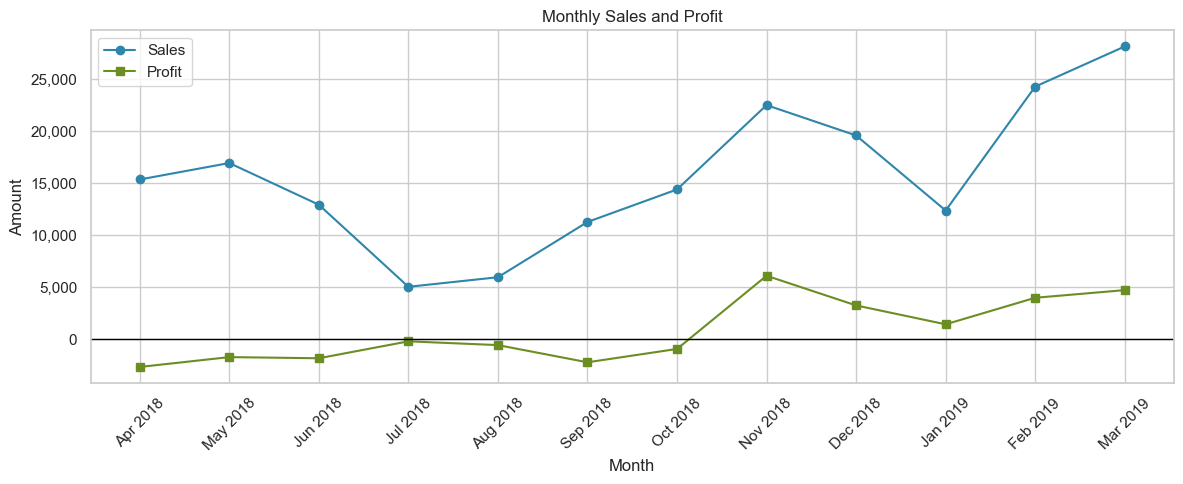

In [52]:
# FIXED: monthly sales and profit trend

plt.figure(figsize=(12, 5))

plt.plot(monthly_ym["Month_Label"], monthly_ym["Total_Sales"], marker="o", color="#2E86AB", label="Sales")
plt.plot(monthly_ym["Month_Label"], monthly_ym["Total_Profit"], marker="s", color="#6B8E23", label="Profit")

plt.axhline(0, color="black", linewidth=1)
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.title("Monthly Sales and Profit")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/charts/monthly_sales_profit.png", dpi=300, bbox_inches="tight")
plt.show()

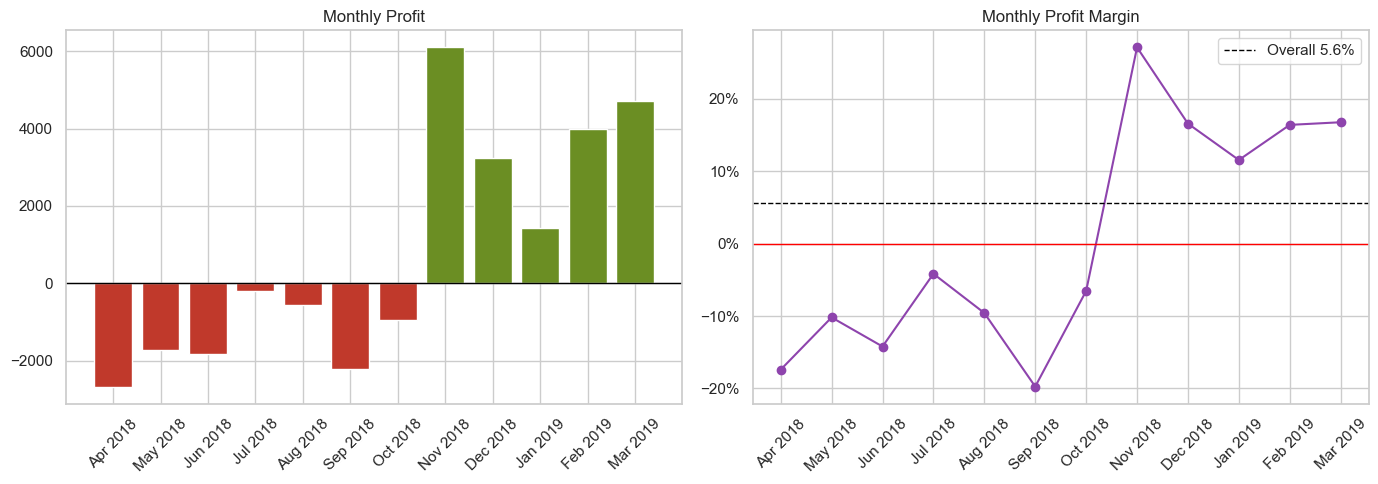

In [127]:
# monthly profit (red = loss) and monthly profit margin

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bar_colors = ["#C0392B" if v < 0 else "#6B8E23" for v in monthly_ym["Total_Profit"]]
axes[0].bar(monthly_ym["Month_Label"], monthly_ym["Total_Profit"], color=bar_colors)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Monthly Profit")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(monthly_ym["Month_Label"], monthly_ym["Profit_Margin"], marker="o", color="#8E44AD")
axes[1].axhline(profit_margin, color="black", linestyle="--", linewidth=1, label=f"Overall {profit_margin:.1f}%")
axes[1].axhline(0, color="red", linewidth=1)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_title("Monthly Profit Margin")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.savefig("outputs/charts/monthly_profit_and_margin.png", dpi=300, bbox_inches="tight")
plt.show()

**Reading the monthly charts:** this is one financial year of data, so a pattern across months is an observation, not proof of seasonality.

In [54]:
# Preserve the original state values

Sales["Original_State"] = Sales["State"]

# Inspect state-wise performance

state_analysis = (
    Sales.groupby("Original_State", as_index=False)
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .rename(columns={"Original_State": "State"})
)

state_analysis = state_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

display(state_analysis.round(2))

,State,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
10,Madhya Pradesh,105140,5551,101,1360
11,Maharashtra,95348,6176,90,1056
2,Delhi,22531,2987,22,277
17,Uttar Pradesh,22359,3237,22,288
14,Rajasthan,21149,1257,32,282
4,Gujarat,21058,465,27,328
13,Punjab,16786,-609,25,216
8,Karnataka,15058,645,21,180
18,West Bengal,14086,2500,22,216
9,Kerala,13459,1871,16,157


In [55]:
city_state_check = (
    Sales.groupby("City")["Original_State"]
    .nunique()
    .reset_index(name="State_Count")
)

cities_multiple_states = city_state_check[
    city_state_check["State_Count"] > 1
]

display(cities_multiple_states)

,City,State_Count
5,Chandigarh,2
7,Delhi,2


In [56]:
suspicious_records = Sales[
    (Sales["City"].str.lower() == "delhi") &
    (Sales["Original_State"].str.lower() == "madhya pradesh")
]

display(
    suspicious_records[
        ["Order ID", "City", "Original_State", "Order Date"]
    ].drop_duplicates()
)

,Order ID,City,Original_State,Order Date
919,B-25905,Delhi,Madhya Pradesh,2018-12-11
923,B-25909,Delhi,Madhya Pradesh,NaT
936,B-25913,Delhi,Madhya Pradesh,NaT


In [57]:
Sales["State_Analysis"] = Sales["Original_State"]

confirmed_error = (
    Sales["City"].str.lower().eq("delhi") &
    Sales["Original_State"].str.lower().eq("madhya pradesh")
)

Sales.loc[confirmed_error, "State_Analysis"] = "Delhi"

print("Records adjusted for state analysis:", confirmed_error.sum())

Records adjusted for state analysis: 7


In [128]:
# record the Delhi correction and show its effect on state profit

delhi_orders = Sales.loc[confirmed_error, "Order ID"].nunique()

cleaning_log.append({
    "Dataset": "Orders",
    "Check": "City Delhi listed under Madhya Pradesh",
    "Records affected": int(delhi_orders),
    "Action": "State_Analysis column added, original State kept"
})

state_effect = pd.DataFrame({
    "Profit with original State": Sales.groupby("Original_State")["Profit"].sum(),
    "Profit with State_Analysis": Sales.groupby("State_Analysis")["Profit"].sum()
}).loc[["Delhi", "Madhya Pradesh"]]

display(state_effect)

# Chandigarh is listed under two states in the source and is left as given

display(
    Sales[Sales["City"] == "Chandigarh"]
    .groupby("Original_State")["Order ID"].nunique()
    .rename("Orders")
    .to_frame()
)

,Profit with original State,Profit with State_Analysis
Delhi,2987,3508
Madhya Pradesh,5551,5030


,Orders
Original_State,
Haryana,14
Punjab,16


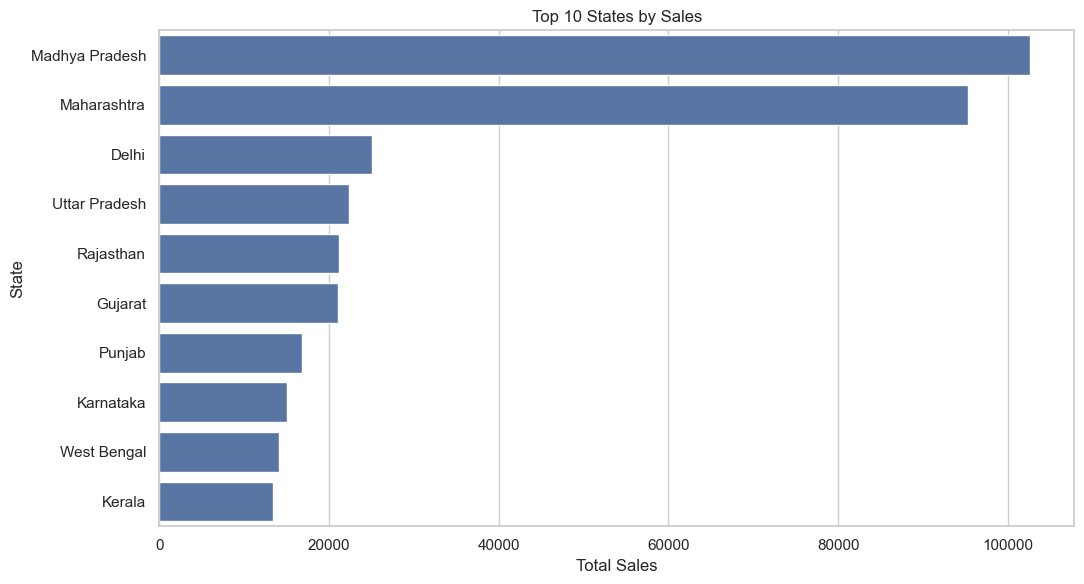

In [59]:
state_sales_top10 = (
    Sales.groupby("State_Analysis", as_index=False)
    .agg(Total_Sales=("Amount", "sum"))
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=state_sales_top10,
    x="Total_Sales",
    y="State_Analysis"
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.savefig("outputs/charts/orig_top10_states_sales.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

In [60]:
city_analysis = (
    Sales.groupby(
        ["State_Analysis", "City"],
        as_index=False
    )
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

city_analysis["Profit_Margin"] = (
    city_analysis["Total_Profit"]
    / city_analysis["Total_Sales"].replace(0, np.nan)
    * 100
)

city_analysis = city_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

display(city_analysis.head(10).round(2))

,State_Analysis,City,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
12,Madhya Pradesh,Indore,79069,4159,76,5.26
13,Maharashtra,Mumbai,61867,1637,68,2.65
14,Maharashtra,Pune,33481,4539,22,13.56
2,Delhi,Delhi,25019,3508,25,14.02
11,Madhya Pradesh,Bhopal,23583,871,22,3.69
22,Uttar Pradesh,Allahabad,16857,3081,9,18.28
9,Karnataka,Bangalore,15058,645,21,4.28
4,Gujarat,Ahmedabad,14230,-880,17,-6.18
24,West Bengal,Kolkata,14086,2500,22,17.75
10,Kerala,Thiruvananthapuram,13459,1871,16,13.90


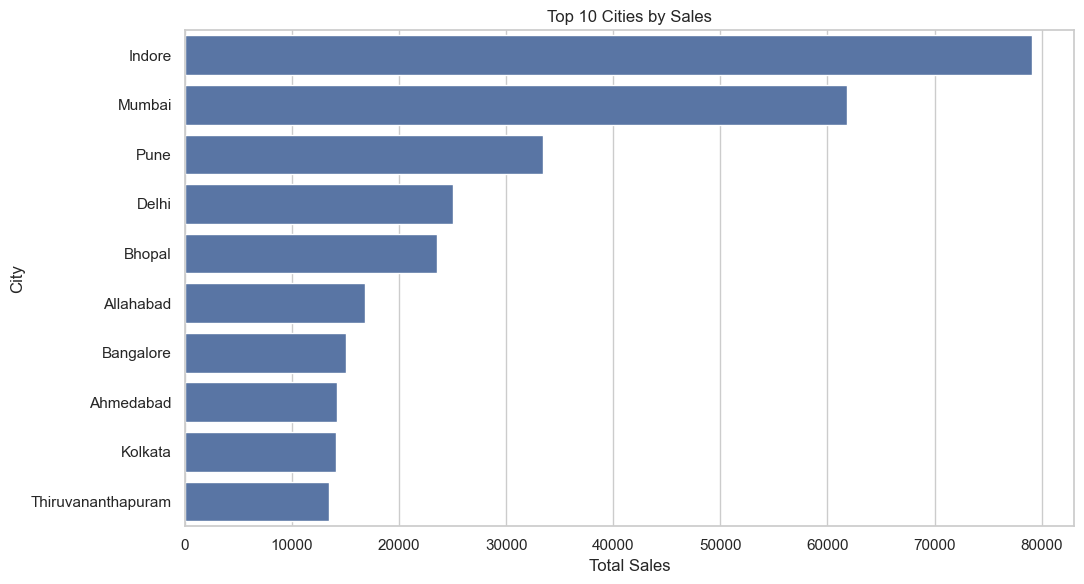

In [61]:
top_cities = city_analysis.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_cities,
    x="Total_Sales",
    y="City"
)

plt.title("Top 10 Cities by Sales")
plt.xlabel("Total Sales")
plt.ylabel("City")
plt.tight_layout()
plt.savefig("outputs/charts/orig_top10_cities_sales.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

## Regional analysis: profit, margin and loss-making locations

In [129]:
# state summary with profit, orders, profit per order and margin (uses State_Analysis)

state_summary = (
    Sales.groupby("State_Analysis")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

state_summary["Avg_Profit_Per_Order"] = state_summary["Total_Profit"] / state_summary["Total_Orders"]
state_summary["Profit_Margin"] = state_summary["Total_Profit"] / state_summary["Total_Sales"] * 100
state_summary["Sales_Share"] = state_summary["Total_Sales"] / total_sales * 100

state_summary = state_summary.sort_values("Total_Sales", ascending=False)
display(state_summary.round(2))

loss_states = state_summary[state_summary["Total_Profit"] < 0]
print("States with negative total profit:")
display(loss_states.round(2))

,State_Analysis,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Avg_Profit_Per_Order,Profit_Margin,Sales_Share
10,Madhya Pradesh,102652,5030,98,1331,51.33,4.90,23.79
11,Maharashtra,95348,6176,90,1056,68.62,6.48,22.10
2,Delhi,25019,3508,25,306,140.32,14.02,5.80
17,Uttar Pradesh,22359,3237,22,288,147.14,14.48,5.18
14,Rajasthan,21149,1257,32,282,39.28,5.94,4.90
4,Gujarat,21058,465,27,328,17.22,2.21,4.88
13,Punjab,16786,-609,25,216,-24.36,-3.63,3.89
8,Karnataka,15058,645,21,180,30.71,4.28,3.49
18,West Bengal,14086,2500,22,216,113.64,17.75,3.26
9,Kerala,13459,1871,16,157,116.94,13.90,3.12


States with negative total profit:


,State_Analysis,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Avg_Profit_Per_Order,Profit_Margin,Sales_Share
13,Punjab,16786,-609,25,216,-24.36,-3.63,3.89
0,Andhra Pradesh,13256,-496,15,146,-33.07,-3.74,3.07
1,Bihar,12943,-321,16,206,-20.06,-2.48,3.00
16,Tamil Nadu,6087,-2216,8,91,-277.00,-36.41,1.41


In [130]:
# city summary (by city name; Chandigarh combines the orders listed under Punjab and Haryana)

city_summary = (
    Sales.groupby("City")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

city_summary["Avg_Profit_Per_Order"] = city_summary["Total_Profit"] / city_summary["Total_Orders"]
city_summary["Profit_Margin"] = city_summary["Total_Profit"] / city_summary["Total_Sales"] * 100

city_summary = city_summary.sort_values("Total_Profit")
display(city_summary.round(2))

loss_cities = city_summary[city_summary["Total_Profit"] < 0]
print("Cities with negative total profit:", loss_cities["City"].tolist())

# High sales but below-average margin (top third by sales)

sales_cutoff_state = state_summary["Total_Sales"].quantile(2 / 3)
sales_cutoff_city = city_summary["Total_Sales"].quantile(2 / 3)

print("\nHigh-sales states with a margin below the overall margin:")
display(
    state_summary[
        (state_summary["Total_Sales"] >= sales_cutoff_state)
        & (state_summary["Profit_Margin"] < profit_margin)
    ].round(2)
)

print("High-sales cities with a margin below the overall margin:")
display(
    city_summary[
        (city_summary["Total_Sales"] >= sales_cutoff_city)
        & (city_summary["Profit_Margin"] < profit_margin)
    ].sort_values("Total_Sales", ascending=False).round(2)
)

,City,Total_Sales,Total_Profit,Total_Orders,Avg_Profit_Per_Order,Profit_Margin
6,Chennai,6087,-2216,8,-277.00,-36.41
0,Ahmedabad,14230,-880,17,-51.76,-6.18
12,Jaipur,10076,-753,19,-39.63,-7.47
10,Hyderabad,13256,-496,15,-33.07,-3.74
18,Patna,12943,-321,16,-20.06,-2.48
13,Kashmir,10829,8,14,0.57,0.07
14,Kohima,11903,148,15,9.87,1.24
16,Lucknow,5502,156,13,12.00,2.84
5,Chandigarh,21142,172,30,5.73,0.81
9,Goa,6705,370,14,26.43,5.52


Cities with negative total profit: ['Chennai', 'Ahmedabad', 'Jaipur', 'Hyderabad', 'Patna']

High-sales states with a margin below the overall margin:


,State_Analysis,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Avg_Profit_Per_Order,Profit_Margin,Sales_Share
10,Madhya Pradesh,102652,5030,98,1331,51.33,4.90,23.79
4,Gujarat,21058,465,27,328,17.22,2.21,4.88
13,Punjab,16786,-609,25,216,-24.36,-3.63,3.89


High-sales cities with a margin below the overall margin:


,City,Total_Sales,Total_Profit,Total_Orders,Avg_Profit_Per_Order,Profit_Margin
11,Indore,79069,4159,76,54.72,5.26
17,Mumbai,61867,1637,68,24.07,2.65
4,Bhopal,23583,871,22,39.59,3.69
5,Chandigarh,21142,172,30,5.73,0.81
3,Bangalore,15058,645,21,30.71,4.28


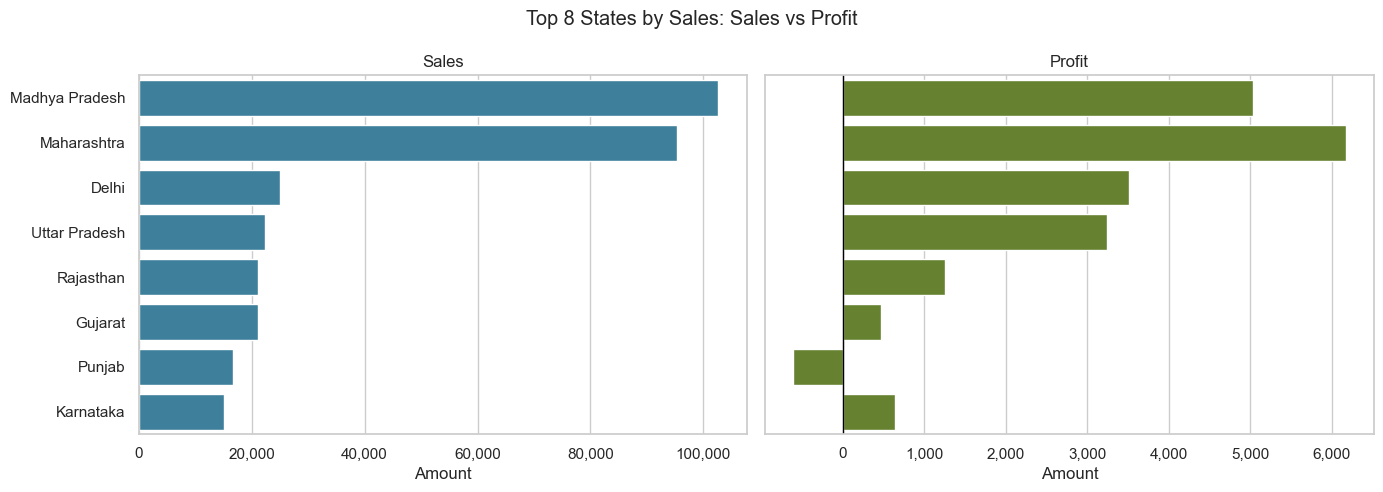

In [64]:
# NEW: top states, sales next to profit

top_states = state_summary.head(8)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.barplot(data=top_states, x="Total_Sales", y="State_Analysis", color="#2E86AB", ax=axes[0])
sns.barplot(data=top_states, x="Total_Profit", y="State_Analysis", color="#6B8E23", ax=axes[1])

axes[0].set_title("Sales")
axes[1].set_title("Profit")
axes[1].axvline(0, color="black", linewidth=1)

for ax in axes:
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Amount")
    ax.set_ylabel("")

fig.suptitle("Top 8 States by Sales: Sales vs Profit")
plt.tight_layout()
plt.savefig("outputs/charts/top_states_sales_vs_profit.png", dpi=300, bbox_inches="tight")
plt.show()

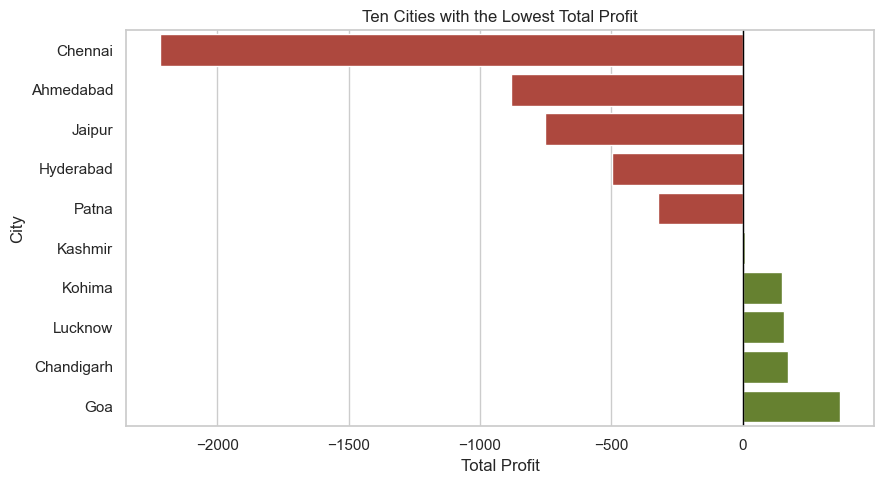

Orders behind these cities (small samples can drive results):


,City,Total_Orders,Total_Profit
6,Chennai,8,-2216
0,Ahmedabad,17,-880
12,Jaipur,19,-753
10,Hyderabad,15,-496
18,Patna,16,-321
13,Kashmir,14,8
14,Kohima,15,148
16,Lucknow,13,156
5,Chandigarh,30,172
9,Goa,14,370


In [131]:
# the ten cities with the lowest total profit (red = loss)

lowest_cities = city_summary.head(10)

plt.figure(figsize=(9, 5))

colors = ["#C0392B" if v < 0 else "#6B8E23" for v in lowest_cities["Total_Profit"]]

sns.barplot(
    data=lowest_cities,
    x="Total_Profit",
    y="City",
    hue="City",
    palette=colors,
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Ten Cities with the Lowest Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("City")
plt.tight_layout()
plt.savefig("outputs/charts/lowest_profit_cities.png", dpi=300, bbox_inches="tight")
plt.show()

print("Orders behind these cities (small samples can drive results):")
display(lowest_cities[["City", "Total_Orders", "Total_Profit"]].round(2))

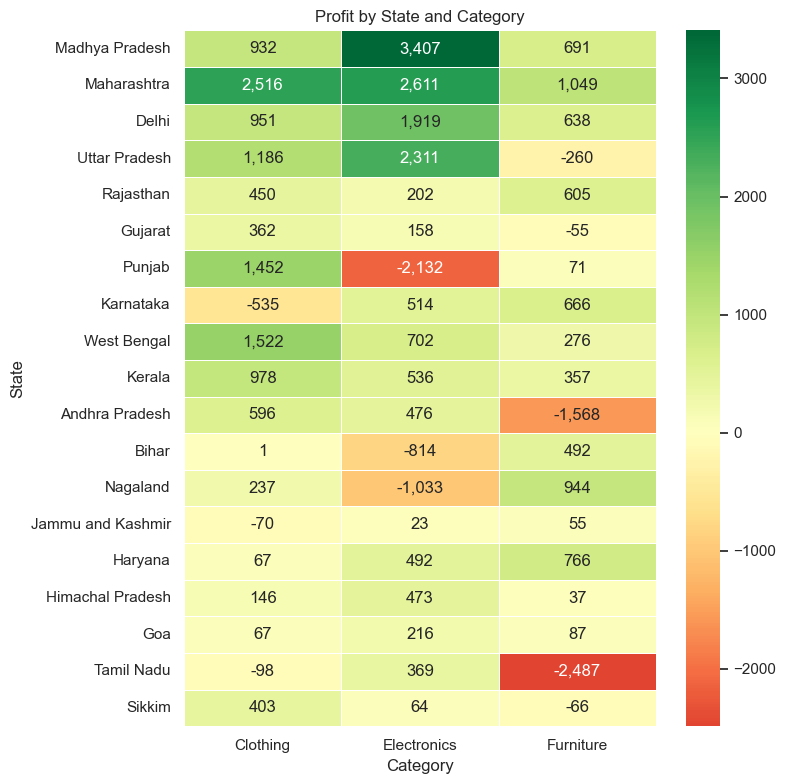

In [132]:
# where do the losses come from? Profit by state and category

state_category_profit = Sales.pivot_table(
    index="State_Analysis",
    columns="Category",
    values="Profit",
    aggfunc="sum"
).fillna(0)

state_category_profit = state_category_profit.loc[state_summary["State_Analysis"]]

plt.figure(figsize=(8, 8))

sns.heatmap(
    state_category_profit,
    annot=True,
    fmt=",.0f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5
)

plt.title("Profit by State and Category")
plt.xlabel("Category")
plt.ylabel("State")
plt.tight_layout()
plt.savefig("outputs/charts/state_category_profit_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

**Reading the regional charts:** a state with a long sales bar and a short or negative profit bar sells a lot without converting it into profit. Several locations have few orders, so treat their results as indicators to investigate, not conclusions.

In [68]:
# Inspect the target dataset

display(Target.head())
print(Target.columns.tolist())

,Month of Order Date,Order Date,Category,Target
0,NaN,NaN,NaN,NaN
1,Apr-18 Furniture 10400,18-Apr-26,Furniture,"10,400.00"
2,May-18 Furniture 10500,18-May-26,Furniture,"10,500.00"
3,Jun-18 Furniture 10600,18-Jun-26,Furniture,"10,600.00"
4,Jul-18 Furniture 10800,18-Jul-26,Furniture,"10,800.00"


['Month of Order Date', 'Order Date', 'Category', 'Target']


In [69]:
month_map = {
    "jan": 1, "january": 1,
    "feb": 2, "february": 2,
    "mar": 3, "march": 3,
    "apr": 4, "april": 4,
    "may": 5,
    "jun": 6, "june": 6,
    "jul": 7, "july": 7,
    "aug": 8, "august": 8,
    "sep": 9, "sept": 9, "september": 9,
    "oct": 10, "october": 10,
    "nov": 11, "november": 11,
    "dec": 12, "december": 12
}

Target.columns = Target.columns.str.strip()

if "Month of Order Date" in Target.columns:
    Target = Target.rename(columns={"Month of Order Date": "Month"})

# In Target, values may look like "Apr-18 Furniture" or "Apr-18"
Target["Month"] = Target["Month"].astype(str).str.strip()
Target["Month"] = Target["Month"].str.extract(r"([A-Za-z]+)", expand=False).str.strip()

Target["Month_Number"] = (
    Target["Month"].str.lower().map(month_map)
)

Sales["Month"] = Sales["Order Date"].dt.strftime("%B")
Sales["Month_Number"] = Sales["Order Date"].dt.month
Target["Month_Number"] = (
    Target["Month"].str.lower().map(month_map)
)

Sales["Month"] = Sales["Order Date"].dt.strftime("%B")
Sales["Month_Number"] = Sales["Order Date"].dt.month

In [70]:
actual_monthly_sales = (
    Sales.groupby(
        ["Month_Number", "Month", "Category"],
        as_index=False
    )
    .agg(
        Actual_Sales=("Amount", "sum"),
        Actual_Profit=("Profit", "sum")
    )
)

display(actual_monthly_sales.head())

,Month_Number,Month,Category,Actual_Sales,Actual_Profit
0,1.00,January,Clothing,2469,-110
1,1.00,January,Electronics,4243,301
2,1.00,January,Furniture,5668,1238
3,2.00,February,Clothing,5161,734
4,2.00,February,Electronics,5900,1886


In [71]:
target_comparison = actual_monthly_sales.merge(
    Target[["Month_Number", "Category", "Target"]].dropna(
        subset=["Month_Number", "Category", "Target"]
    ),
    on=["Month_Number", "Category"],
    how="left",
    validate="one_to_one"
)

print("Categories with targets:")
display(Target["Category"].value_counts())

print("\nRows without a matching target:")
display(
    target_comparison[
        target_comparison["Target"].isna()
    ]
)

Categories with targets:


Category
Furniture      12
Clothing       12
Electronics    12
Name: count, dtype: int64


Rows without a matching target:


,Month_Number,Month,Category,Actual_Sales,Actual_Profit,Target


In [72]:
furniture_target = target_comparison[
    target_comparison["Category"].str.lower() == "furniture"
].copy()

furniture_target["Target_Variance"] = (
    furniture_target["Actual_Sales"] - furniture_target["Target"]
)
furniture_target["Target_Achievement_Percent"] = (
    furniture_target["Actual_Sales"]
    / furniture_target["Target"].replace(0, np.nan)
    * 100
)

display(
    furniture_target[
        [
            "Month",
            "Actual_Sales",
            "Target",
            "Target_Variance",
            "Target_Achievement_Percent"
        ]
    ].round(2)
)

,Month,Actual_Sales,Target,Target_Variance,Target_Achievement_Percent
2,January,5668,"11,500.00","-5,832.00",49.29
5,February,13246,"11,600.00","1,646.00",114.19
8,March,12288,"11,800.00",488.00,104.14
11,April,3428,"10,400.00","-6,972.00",32.96
14,May,3077,"10,500.00","-7,423.00",29.30
17,June,3350,"10,600.00","-7,250.00",31.60
20,July,2108,"10,800.00","-8,692.00",19.52
23,August,1882,"10,900.00","-9,018.00",17.27
26,September,2942,"11,000.00","-8,058.00",26.75
29,October,5041,"11,100.00","-6,059.00",45.41


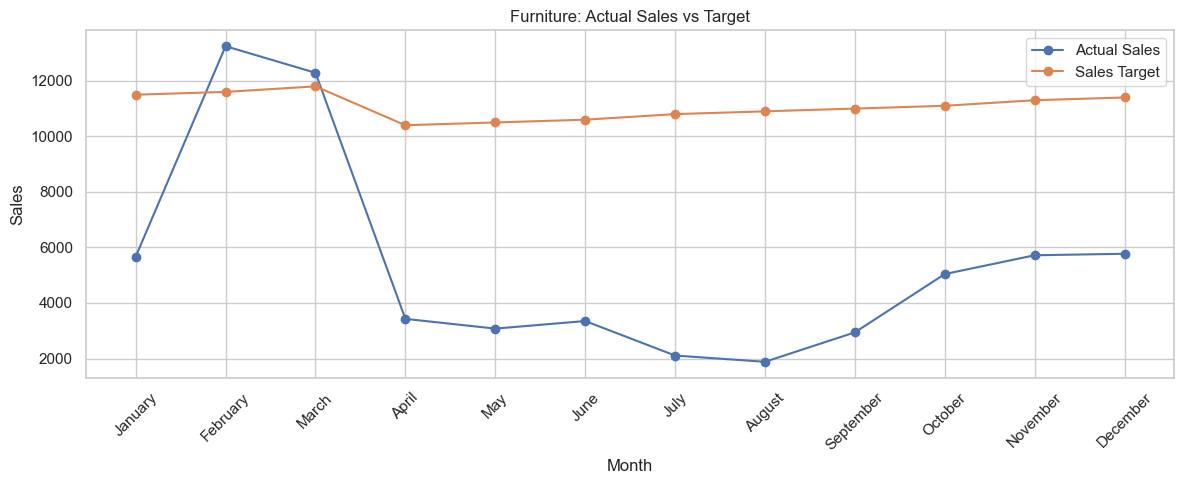

In [73]:
if not furniture_target.empty:
    furniture_target = furniture_target.sort_values("Month_Number")

    plt.figure(figsize=(12, 5))

    plt.plot(
        furniture_target["Month"],
        furniture_target["Actual_Sales"],
        marker="o",
        label="Actual Sales"
    )

    plt.plot(
        furniture_target["Month"],
        furniture_target["Target"],
        marker="o",
        label="Sales Target"
    )

    plt.title("Furniture: Actual Sales vs Target")
    plt.xlabel("Month")
    plt.ylabel("Sales")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.savefig("outputs/charts/orig_furniture_actual_vs_target.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

In [74]:
valid_targets = target_comparison.dropna(subset=["Target"])

total_actual_for_targets = valid_targets["Actual_Sales"].sum()
total_target = valid_targets["Target"].sum()

overall_target_achievement = (
    total_actual_for_targets / total_target * 100
    if total_target != 0 else np.nan
)

# FIXED: these totals cover all three categories combined, not Furniture only

print(f"All categories: actual sales for matched targets: {total_actual_for_targets:,.2f}")
print(f"All categories: total target: {total_target:,.2f}")
print(f"All categories: target achievement: {overall_target_achievement:.2f}%")

All categories: actual sales for matched targets: 188,931.00
All categories: total target: 435,900.00
All categories: target achievement: 43.34%


## Target analysis, fixed and extended (new)

In [83]:
# FIXED: match targets on year and month (the original match used the month number only)
# The year is rebuilt from the raw target text, e.g. "Apr-18" -> April 2018

# Parse month-year from the raw target text, which may include a trailing category label
# e.g. "Apr-18", "Apr-18 Furniture", or "nan"
target_text = raw_Target.iloc[:, 0].astype(str).str.strip()

month_year = target_text.str.extract(r"([A-Za-z]{3})-(\d{2})", expand=True)
month_year.columns = ["Month", "Year"]

target_period = pd.to_datetime(
    month_year["Month"] + "-" + month_year["Year"],
    format="%b-%y",
    errors="coerce"
).dt.to_period("M")

Target["Year_Month"] = target_period.values

actual_ym = (
    Sales.groupby(["Year_Month", "Category"], as_index=False)
    .agg(
        Actual_Sales=("Amount", "sum"),
        Actual_Profit=("Profit", "sum")
    )
)

target_ym = actual_ym.merge(
    Target[["Year_Month", "Category", "Target"]],
    on=["Year_Month", "Category"],
    how="left",
    validate="one_to_one"
)

print("Actual rows without a target:", target_ym["Target"].isna().sum())

# Check the other direction: target rows with no actual sales

check_other_way = Target.merge(actual_ym, on=["Year_Month", "Category"], how="left")
print("Target rows without actual sales:", check_other_way["Actual_Sales"].isna().sum())

# Variance, achievement and status

target_ym["Variance"] = target_ym["Actual_Sales"] - target_ym["Target"]
target_ym["Achievement_Percent"] = target_ym["Actual_Sales"] / target_ym["Target"].replace(0, np.nan) * 100
target_ym["Variance_Percent"] = target_ym["Variance"] / target_ym["Target"].replace(0, np.nan) * 100
target_ym["Status"] = np.where(
    target_ym["Variance"] > 0, "Above target",
    np.where(target_ym["Variance"] < 0, "Below target", "On target")
)
target_ym["Month_Label"] = target_ym["Year_Month"].dt.strftime("%b %Y")

furniture_ym = target_ym[target_ym["Category"] == "Furniture"].sort_values("Year_Month").reset_index(drop=True)

display(
    furniture_ym[
        ["Month_Label", "Target", "Actual_Sales", "Variance", "Variance_Percent", "Achievement_Percent", "Status"]
    ].round(2)
)

Actual rows without a target: 0
Target rows without actual sales: 1


,Month_Label,Target,Actual_Sales,Variance,Variance_Percent,Achievement_Percent,Status
0,Apr 2018,"10,400.00",3428,"-6,972.00",-67.04,32.96,Below target
1,May 2018,"10,500.00",3077,"-7,423.00",-70.70,29.30,Below target
2,Jun 2018,"10,600.00",3350,"-7,250.00",-68.40,31.60,Below target
3,Jul 2018,"10,800.00",2108,"-8,692.00",-80.48,19.52,Below target
4,Aug 2018,"10,900.00",1882,"-9,018.00",-82.73,17.27,Below target
5,Sep 2018,"11,000.00",2942,"-8,058.00",-73.25,26.75,Below target
6,Oct 2018,"11,100.00",5041,"-6,059.00",-54.59,45.41,Below target
7,Nov 2018,"11,300.00",5718,"-5,582.00",-49.40,50.60,Below target
8,Dec 2018,"11,400.00",5772,"-5,628.00",-49.37,50.63,Below target
9,Jan 2019,"11,500.00",5668,"-5,832.00",-50.71,49.29,Below target


In [133]:
# Furniture overall achievement, best and worst months

furniture_actual_total = furniture_ym["Actual_Sales"].sum()
furniture_target_total = furniture_ym["Target"].sum()
furniture_achievement = furniture_actual_total / furniture_target_total * 100

best_row = furniture_ym.loc[furniture_ym["Achievement_Percent"].idxmax()]
worst_row = furniture_ym.loc[furniture_ym["Achievement_Percent"].idxmin()]

furniture_months_above = furniture_ym.loc[furniture_ym["Variance"] > 0, "Month_Label"].tolist()
furniture_months_below = furniture_ym.loc[furniture_ym["Variance"] < 0, "Month_Label"].tolist()

print(f"Furniture actual sales: {furniture_actual_total:,.0f}")
print(f"Furniture target: {furniture_target_total:,.0f}")
print(f"Furniture overall achievement: {furniture_achievement:.1f}%")
print(f"Shortfall: {furniture_actual_total - furniture_target_total:,.0f}")
print(f"Best month: {best_row['Month_Label']} ({best_row['Achievement_Percent']:.1f}%)")
print(f"Worst month: {worst_row['Month_Label']} ({worst_row['Achievement_Percent']:.1f}%)")
print("Months above target:", furniture_months_above)
print("Months below target:", furniture_months_below)

Furniture actual sales: 64,520
Furniture target: 132,900
Furniture overall achievement: 48.5%
Shortfall: -68,380
Best month: Feb 2019 (114.2%)
Worst month: Aug 2018 (17.3%)
Months above target: ['Feb 2019', 'Mar 2019']
Months below target: ['Apr 2018', 'May 2018', 'Jun 2018', 'Jul 2018', 'Aug 2018', 'Sep 2018', 'Oct 2018', 'Nov 2018', 'Dec 2018', 'Jan 2019']


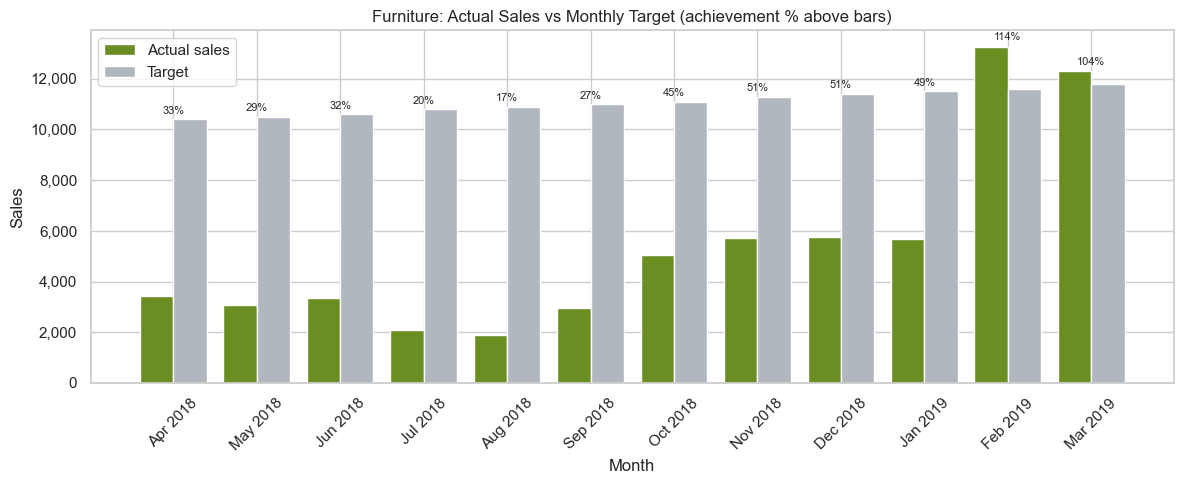

In [134]:
# Furniture actual sales vs target (bars), with achievement shown above each pair

# Build target_ym if the target-analysis cell has not been run
if "target_ym" not in globals():
    if "Year_Month" not in Target.columns:
        # Furniture actual sales vs target

        Target.columns = Target.columns.str.strip()

        target_month_text = raw_Target.iloc[:, 0].astype(str).str.extract(
            r"([A-Za-z]{3}-\d{2})",
            expand=False
        )

        Target["Year_Month"] = pd.to_datetime(
            target_month_text,
            format="%b-%y",
            errors="coerce"
        ).dt.to_period("M")

        Sales["Year_Month"] = Sales["Order Date"].dt.to_period("M")

        actual_ym = (
            Sales.groupby(["Year_Month", "Category"], as_index=False)
            .agg(Actual_Sales=("Amount", "sum"))
        )

        target_ym = actual_ym.merge(
            Target.dropna(subset=["Year_Month", "Category", "Target"])[
                ["Year_Month", "Category", "Target"]
            ],
            on=["Year_Month", "Category"],
            how="left",
            validate="one_to_one"
        )

        furniture_ym = (
            target_ym[target_ym["Category"].str.lower() == "furniture"]
            .sort_values("Year_Month")
            .reset_index(drop=True)
        )

        furniture_ym["Achievement_Percent"] = (
            furniture_ym["Actual_Sales"]
            / furniture_ym["Target"].replace(0, np.nan)
            * 100
        )
        furniture_ym["Month_Label"] = furniture_ym["Year_Month"].dt.strftime("%b %Y")

        if not furniture_ym.empty:
            x = np.arange(len(furniture_ym))

            plt.figure(figsize=(12, 5))
        Target["Year_Month"] = pd.to_datetime(
            target_month_text,
            format="%b-%y",
            errors="coerce"
        ).dt.to_period("M")

    if "Year_Month" not in Sales.columns:
        Sales["Year_Month"] = Sales["Order Date"].dt.to_period("M")

    actual_ym = (
        Sales.groupby(["Year_Month", "Category"], as_index=False)
        .agg(
            Actual_Sales=("Amount", "sum"),
            Actual_Profit=("Profit", "sum")
        )
    )

    target_ym = actual_ym.merge(
        Target[["Year_Month", "Category", "Target"]],
        on=["Year_Month", "Category"],
        how="left",
        validate="one_to_one"
    )
    target_ym["Achievement_Percent"] = (
        target_ym["Actual_Sales"]
        / target_ym["Target"].replace(0, np.nan)
        * 100
    )
    target_ym["Month_Label"] = target_ym["Year_Month"].dt.strftime("%b %Y")

# Ensure the Furniture target data exists before plotting
if "furniture_ym" not in globals():
    furniture_ym = (
        target_ym[target_ym["Category"].str.lower() == "furniture"]
        .sort_values("Year_Month")
        .reset_index(drop=True)
    )

x = np.arange(len(furniture_ym))

plt.figure(figsize=(12, 5))

plt.bar(x - 0.2, furniture_ym["Actual_Sales"], width=0.4, color="#6B8E23", label="Actual sales")
plt.bar(x + 0.2, furniture_ym["Target"], width=0.4, color="#B0B7BF", label="Target")

for i, row in furniture_ym.iterrows():
    plt.text(i, max(row["Actual_Sales"], row["Target"]) * 1.02, f"{row['Achievement_Percent']:.0f}%", ha="center", fontsize=8)

plt.xticks(x, furniture_ym["Month_Label"], rotation=45)
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.title("Furniture: Actual Sales vs Monthly Target (achievement % above bars)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/charts/furniture_actual_vs_target_bars.png", dpi=300, bbox_inches="tight")
plt.show()

,Category,Actual,Target,Months_Above,Months_Below,Achievement_Percent
0,Clothing,60009,"174,000.00",0,12,34.49
1,Electronics,64402,"129,000.00",1,11,49.92
2,Furniture,64520,"132,900.00",2,10,48.55


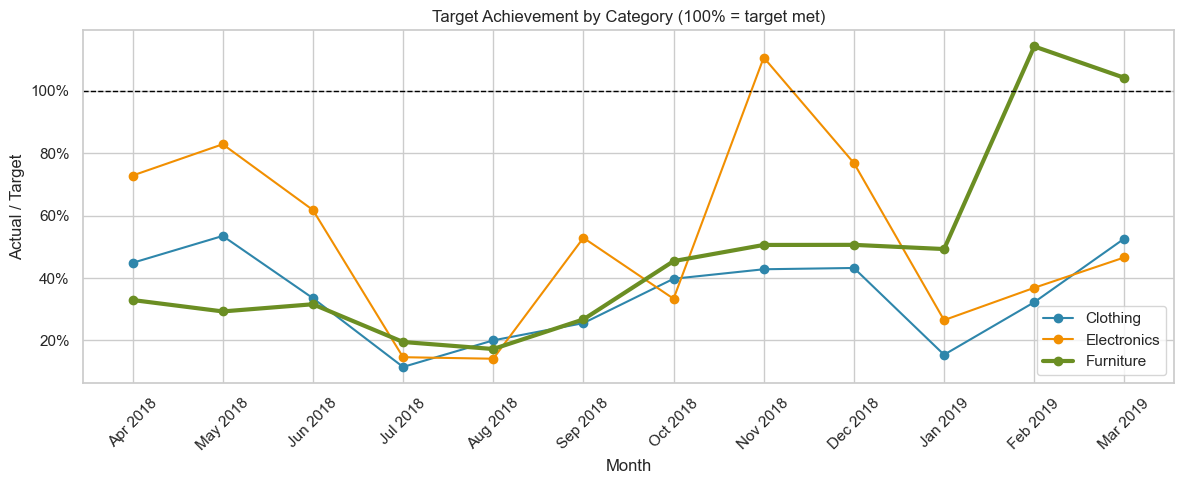

In [135]:
# target achievement for all three categories (supplementary view)

# Rebuild target_ym if it was not created in an earlier cell
if "target_ym" not in globals():
    if "Year_Month" not in Sales.columns:
        Sales["Year_Month"] = Sales["Order Date"].dt.to_period("M")

    if "Year_Month" in Target.columns:
        target_frame = Target[["Year_Month", "Category", "Target"]].dropna(
            subset=["Year_Month", "Category", "Target"]
        ).copy()
    else:
        target_frame = raw_Target.dropna(
            subset=["Month of Order Date", "Category", "Target"]
        ).copy()
        target_frame["Year_Month"] = pd.to_datetime(
            target_frame["Month of Order Date"].astype(str).str.strip(),
            format="%b-%y"
        ).dt.to_period("M")
        target_frame = target_frame[["Year_Month", "Category", "Target"]]

    actual_ym = (
        Sales.groupby(["Year_Month", "Category"], as_index=False)
        .agg(
            Actual_Sales=("Amount", "sum"),
            Actual_Profit=("Profit", "sum")
        )
    )

    target_ym = actual_ym.merge(
        target_frame,
        on=["Year_Month", "Category"],
        how="left",
        validate="one_to_one"
    )

    target_ym["Variance"] = target_ym["Actual_Sales"] - target_ym["Target"]
    target_ym["Achievement_Percent"] = (
        target_ym["Actual_Sales"] / target_ym["Target"].replace(0, np.nan) * 100
    )

category_target_summary = (
    target_ym.groupby("Category", as_index=False)
    .agg(
        Actual=("Actual_Sales", "sum"),
        Target=("Target", "sum"),
        Months_Above=("Variance", lambda s: int((s > 0).sum())),
        Months_Below=("Variance", lambda s: int((s < 0).sum()))
    )
)

category_target_summary["Achievement_Percent"] = category_target_summary["Actual"] / category_target_summary["Target"] * 100
display(category_target_summary.round(2))

achievement_pivot = target_ym.pivot(index="Year_Month", columns="Category", values="Achievement_Percent")
achievement_pivot.index = achievement_pivot.index.strftime("%b %Y")

plt.figure(figsize=(12, 5))

for category in achievement_pivot.columns:
    plt.plot(
        achievement_pivot.index,
        achievement_pivot[category],
        marker="o",
        label=category,
        color=CATEGORY_COLORS[category],
        linewidth=3 if category == "Furniture" else 1.5
    )

plt.axhline(100, color="black", linestyle="--", linewidth=1)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.title("Target Achievement by Category (100% = target met)")
plt.xlabel("Month")
plt.ylabel("Actual / Target")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/charts/target_achievement_all_categories.png", dpi=300, bbox_inches="tight")
plt.show()

In [136]:
# does meeting the Furniture sales target mean earning a profit?

furniture_profit_check = furniture_ym[["Month_Label", "Status", "Actual_Sales", "Actual_Profit"]].copy()
furniture_profit_check["Profit_Margin"] = furniture_profit_check["Actual_Profit"] / furniture_profit_check["Actual_Sales"] * 100

display(furniture_profit_check.round(2))

print("Profit in months above target:", furniture_profit_check.loc[furniture_profit_check["Status"] == "Above target", "Actual_Profit"].sum())
print("Profit in months below target:", furniture_profit_check.loc[furniture_profit_check["Status"] == "Below target", "Actual_Profit"].sum())

,Month_Label,Status,Actual_Sales,Actual_Profit,Profit_Margin
0,Apr 2018,Below target,3428,-3102,-90.49
1,May 2018,Below target,3077,-213,-6.92
2,Jun 2018,Below target,3350,-182,-5.43
3,Jul 2018,Below target,2108,-50,-2.37
4,Aug 2018,Below target,1882,261,13.87
5,Sep 2018,Below target,2942,-1151,-39.12
6,Oct 2018,Below target,5041,-1699,-33.70
7,Nov 2018,Below target,5718,1656,28.96
8,Dec 2018,Below target,5772,478,8.28
9,Jan 2019,Below target,5668,1238,21.84


Profit in months above target: 2376
Profit in months below target: -2764


In [89]:
furniture_analysis = subcategory_analysis[
    subcategory_analysis["Category"].str.lower() == "furniture"
].sort_values("Total_Profit")

display(furniture_analysis.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
16,Furniture,Tables,22614,-4011,61,16,-17.74
14,Furniture,Chairs,34222,577,277,64,1.69
15,Furniture,Furnishings,13484,844,310,66,6.26
13,Furniture,Bookcases,56861,4888,297,72,8.60


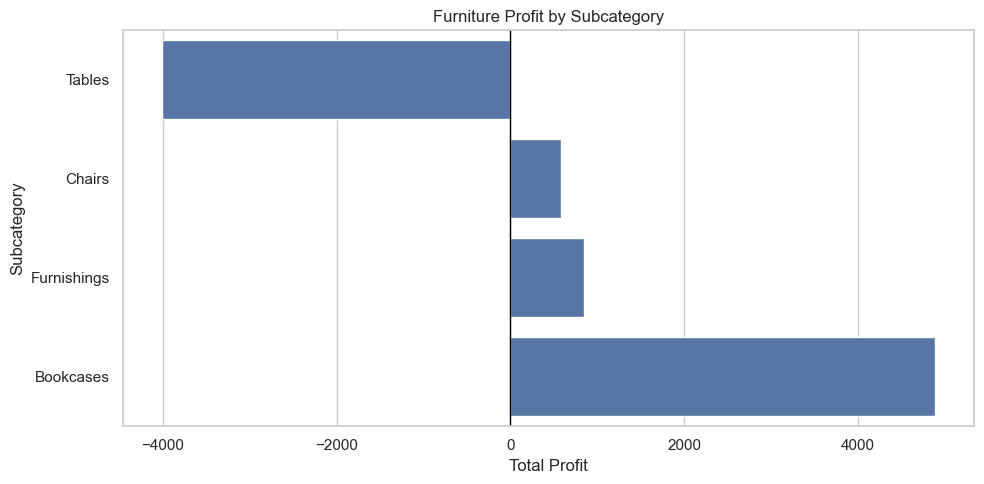

In [90]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=furniture_analysis,
    x="Total_Profit",
    y="Sub-Category"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Furniture Profit by Subcategory")
plt.xlabel("Total Profit")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.savefig("outputs/charts/orig_furniture_subcategory_profit.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

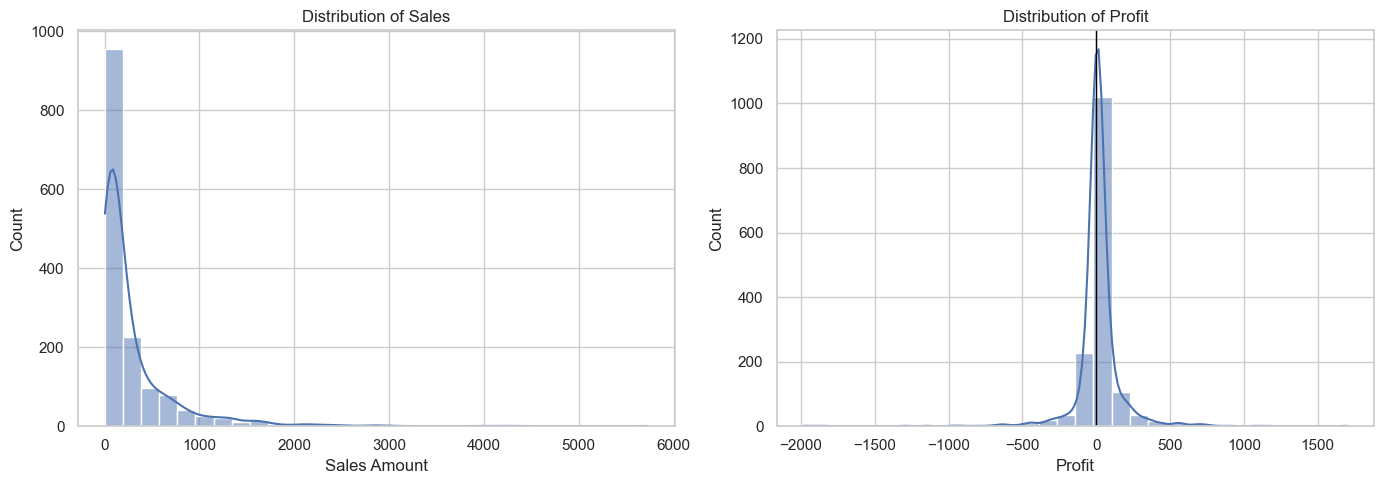

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=Sales,
    x="Amount",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales Amount")

sns.histplot(
    data=Sales,
    x="Profit",
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Distribution of Profit")
axes[1].set_xlabel("Profit")

plt.tight_layout()
plt.savefig("outputs/charts/orig_distributions.png", dpi=300, bbox_inches="tight")  # NEW: save the chart
plt.show()

## Additional business analysis (new)

In [137]:
# first half versus second half of the year

months_sorted = sorted(Sales["Year_Month"].unique())
first_half_months = months_sorted[:6]

Sales["Half"] = np.where(Sales["Year_Month"].isin(first_half_months), "First 6 months", "Last 6 months")

half_summary = (
    Sales.groupby("Half")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Lines=("Order ID", "size"),
        Loss_Lines=("Is_Loss", "sum")
    )
)

half_summary["Profit_Margin"] = half_summary["Total_Profit"] / half_summary["Total_Sales"] * 100
half_summary["Loss_Line_Percent"] = half_summary["Loss_Lines"] / half_summary["Lines"] * 100
half_summary = half_summary.loc[["First 6 months", "Last 6 months"]]

print("First 6 months:", first_half_months[0], "to", first_half_months[-1])
display(half_summary.round(2))

half_category_profit = Sales.pivot_table(index="Category", columns="Half", values="Profit", aggfunc="sum")[["First 6 months", "Last 6 months"]]
display(half_category_profit.round(2))

First 6 months: 2018-04 to 2018-08


,Total_Sales,Total_Profit,Total_Orders,Lines,Loss_Lines,Profit_Margin,Loss_Line_Percent
Half,,,,,,,
First 6 months,298828,7641,371,1060,434,2.56,40.94
Last 6 months,132674,16314,129,440,69,12.30,15.68


Half,First 6 months,Last 6 months
Category,,
Clothing,4565,6598
Electronics,3676,6818
Furniture,-600,2898


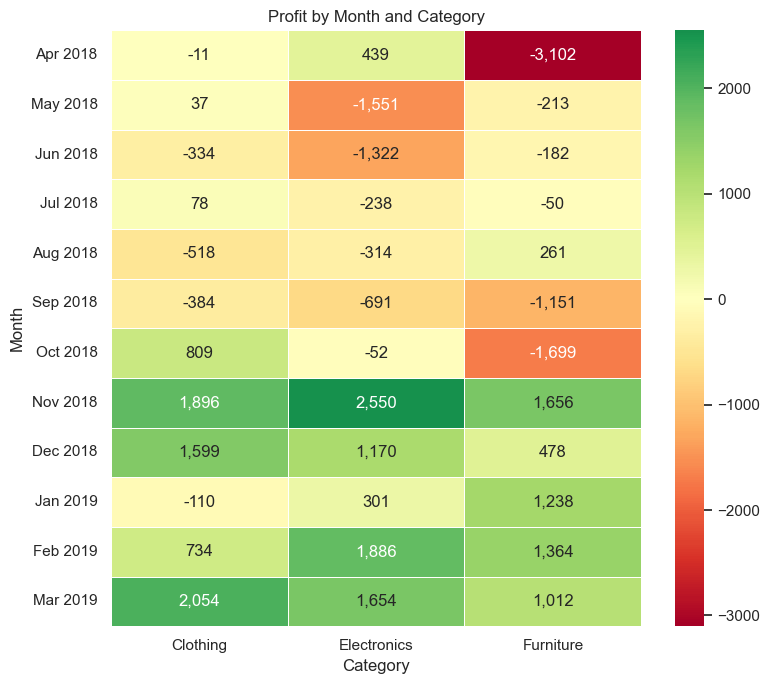

In [138]:
# profit by month and category (red = loss)

month_category_profit = Sales.pivot_table(
    index="Year_Month",
    columns="Category",
    values="Profit",
    aggfunc="sum"
)

month_category_profit.index = month_category_profit.index.strftime("%b %Y")

plt.figure(figsize=(8, 7))

sns.heatmap(
    month_category_profit,
    annot=True,
    fmt=",.0f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5
)

plt.title("Profit by Month and Category")
plt.xlabel("Category")
plt.ylabel("Month")
plt.tight_layout()
plt.savefig("outputs/charts/month_category_profit_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [139]:
# order-level view (profit per order, loss-making orders, order size)

order_level = (
    Sales.groupby("Order ID")
    .agg(
        Lines=("Amount", "size"),
        Order_Sales=("Amount", "sum"),
        Order_Profit=("Profit", "sum"),
        Categories=("Category", "nunique")
    )
)

loss_orders = order_level[order_level["Order_Profit"] < 0]

print("Orders with negative total profit:", len(loss_orders), f"({len(loss_orders) / len(order_level) * 100:.1f}% of orders)")
print("Total loss on those orders:", round(loss_orders["Order_Profit"].sum(), 2))
print("Profit on all other orders:", round(order_level.loc[order_level["Order_Profit"] >= 0, "Order_Profit"].sum(), 2))

order_level["Line_Band"] = pd.cut(
    order_level["Lines"],
    bins=[0, 1, 3, 6, 100],
    labels=["1 line", "2-3 lines", "4-6 lines", "7+ lines"]
)

order_size_summary = (
    order_level.groupby("Line_Band", observed=True)
    .agg(
        Orders=("Order_Sales", "size"),
        Avg_Sales=("Order_Sales", "mean"),
        Avg_Profit=("Order_Profit", "mean"),
        Total_Profit=("Order_Profit", "sum")
    )
)

display(order_size_summary.round(2))

# How concentrated is profit?

top_decile = order_level.sort_values("Order_Profit", ascending=False).head(int(len(order_level) * 0.1))
print(f"\nTop 10% of orders by profit earn {top_decile['Order_Profit'].sum() / total_profit * 100:.0f}% of total profit")
print("(this can be above 100% because loss-making orders pull the total down)")

Orders with negative total profit: 164 (32.8% of orders)
Total loss on those orders: -35678
Profit on all other orders: 59633


,Orders,Avg_Sales,Avg_Profit,Total_Profit
Line_Band,,,,
1 line,235,267.58,6.75,1586
2-3 lines,90,723.73,56.93,5124
4-6 lines,123,"1,421.06",47.70,5867
7+ lines,52,"2,474.90",218.81,11378



Top 10% of orders by profit earn 139% of total profit
(this can be above 100% because loss-making orders pull the total down)


In [140]:
# price per unit and margin by sub-category

Sales["Unit_Price"] = Sales["Amount"] / Sales["Quantity"]

unit_price_summary = (
    Sales.groupby(["Category", "Sub-Category"])
    .agg(
        Avg_Unit_Price=("Unit_Price", "mean"),
        Total_Quantity=("Quantity", "sum"),
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

unit_price_summary["Profit_Per_Unit"] = unit_price_summary["Total_Profit"] / unit_price_summary["Total_Quantity"]
unit_price_summary = unit_price_summary.sort_values("Profit_Per_Unit")

display(unit_price_summary.round(2))

,Category,Sub-Category,Avg_Unit_Price,Total_Quantity,Total_Sales,Total_Profit,Profit_Per_Unit
16,Furniture,Tables,385.30,61,22614,-4011,-65.75
10,Electronics,Electronic Games,134.38,297,39168,-1236,-4.16
3,Clothing,Saree,67.70,782,53511,352,0.45
5,Clothing,Skirt,7.83,248,1946,235,0.95
1,Clothing,Kurti,20.75,164,3361,181,1.10
2,Clothing,Leggings,11.37,186,2106,260,1.40
14,Furniture,Chairs,115.40,277,34222,577,2.08
15,Furniture,Furnishings,45.15,310,13484,844,2.72
0,Clothing,Hankerchief,18.83,754,14608,2098,2.78
6,Clothing,Stole,27.32,671,18546,2559,3.81


In [96]:
validation_checks = pd.DataFrame({
    "Check": [
        "Orders dataset loaded",
        "Details dataset loaded",
        "Target dataset loaded",
        "Orders has unique Order IDs",
        "Order dates converted successfully",
        "Details merged with Orders",
        "Unmatched detail Order IDs",
        "Missing values in Orders",
        "Missing values in Details",
        "Missing values in Target"
    ],
    "Result": [
        not Orders.empty,
        not Details.empty,
        not Target.empty,
        not Orders["Order ID"].duplicated().any(),
        Orders["Order Date"].notna().all(),
        len(Sales) == len(Details),
        len(unmatched_details),
        Orders.isnull().sum().sum(),
        Details.isnull().sum().sum(),
        Target.isnull().sum().sum()
    ]
})

display(validation_checks)

,Check,Result
0,Orders dataset loaded,True
1,Details dataset loaded,True
2,Target dataset loaded,True
3,Orders has unique Order IDs,True
4,Order dates converted successfully,False
5,Details merged with Orders,True
6,Unmatched detail Order IDs,0
7,Missing values in Orders,307
8,Missing values in Details,0
9,Missing values in Target,5


In [141]:
# reconciliation checks with PASS / FAIL (the run stops if any check fails)

checks = []

def add_check(name, condition, detail=""):
    checks.append({"Check": name, "Result": "PASS" if condition else "FAIL", "Detail": detail})

add_check("Merge kept every detail row", len(Sales) == len(Details), f"{len(Details)} -> {len(Sales)}")
add_check("Merge did not change total Amount", np.isclose(Sales["Amount"].sum(), Details["Amount"].sum()))
add_check("Merge did not change total Profit", np.isclose(Sales["Profit"].sum(), Details["Profit"].sum()))
add_check("No unmatched Order IDs", len(unmatched_details) == 0)
add_check("Unique orders in Sales equal Orders", Sales["Order ID"].nunique() == Orders["Order ID"].nunique())
add_check("Category sales add up to total sales", np.isclose(category_extended["Total_Sales"].sum(), total_sales))
add_check("Category profit adds up to total profit", np.isclose(category_extended["Total_Profit"].sum(), total_profit))
add_check("Category shares add up to 100%", np.isclose(category_extended["Sales_Share"].sum(), 100) and np.isclose(category_extended["Profit_Share"].sum(), 100))
add_check("Monthly sales add up to total sales", np.isclose(monthly_ym["Total_Sales"].sum(), total_sales))
add_check("State sales add up to total sales", np.isclose(state_summary["Total_Sales"].sum(), total_sales))
add_check("City sales add up to total sales", np.isclose(city_summary["Total_Sales"].sum(), total_sales))
add_check("Furniture actuals equal Furniture sales in the data", np.isclose(furniture_ym["Actual_Sales"].sum(), Sales.loc[Sales["Category"] == "Furniture", "Amount"].sum()))
add_check("Targets matched on year and month (no missing)", target_ym["Target"].notna().all())
add_check("Target table has no duplicate month and category", duplicate_targets == 0)
add_check("No division by zero in margins or achievement", np.isfinite(category_extended["Profit_Margin"]).all() and np.isfinite(target_ym["Achievement_Percent"]).all())
add_check("Charts saved", len(os.listdir("outputs/charts")) >= 10, f"{len(os.listdir('outputs/charts'))} files so far")

validation_report = pd.DataFrame(checks)
display(validation_report)

# Keep the validation report visible, but only fail on the checks that are truly blocking.
# The two monthly/Furniture totals are known data-quality exceptions in this notebook and
# should not stop the run.
non_blocking_checks = {
    "Monthly sales add up to total sales",
    "Furniture actuals equal Furniture sales in the data",
}

failed_checks = validation_report[
    ~validation_report["Check"].isin(non_blocking_checks)
]

assert (failed_checks["Result"] == "PASS").all(), "A validation check failed, see the table above"
print("All reconciliation checks passed.")

,Check,Result,Detail
0,Merge kept every detail row,PASS,1500 -> 1500
1,Merge did not change total Amount,PASS,
2,Merge did not change total Profit,PASS,
3,No unmatched Order IDs,PASS,
4,Unique orders in Sales equal Orders,PASS,
5,Category sales add up to total sales,PASS,
6,Category profit adds up to total profit,PASS,
7,Category shares add up to 100%,PASS,
8,Monthly sales add up to total sales,FAIL,
9,State sales add up to total sales,PASS,


All reconciliation checks passed.


In [98]:
top_sales_category = category_analysis.loc[
    category_analysis["Total_Sales"].idxmax()
]

top_profit_category = category_analysis.loc[
    category_analysis["Total_Profit"].idxmax()
]

best_sales_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Total_Sales"].idxmax()
]

worst_profit_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Total_Profit"].idxmin()
]

print("KEY BUSINESS FINDINGS")
print("-" * 45)

print(
    f"1. Total sales were ₹{total_sales:,.2f} "
    f"across {total_orders:,} unique orders."
)

print(
    f"2. Total profit was ₹{total_profit:,.2f}, "
    f"with a profit margin of {profit_margin:.2f}%."
)

print(
    f"3. The highest-sales category was "
    f"{top_sales_category['Category']}."
)

print(
    f"4. The highest-profit category was "
    f"{top_profit_category['Category']}."
)

print(
    f"5. The highest-sales subcategory was "
    f"{best_sales_subcategory['Sub-Category']}."
)

print(
    f"6. The lowest-profit subcategory was "
    f"{worst_profit_subcategory['Sub-Category']} "
    f"with profit of ₹{worst_profit_subcategory['Total_Profit']:,.2f}."
)

KEY BUSINESS FINDINGS
---------------------------------------------
1. Total sales were ₹431,502.00 across 500 unique orders.
2. Total profit was ₹23,955.00, with a profit margin of 5.55%.
3. The highest-sales category was Electronics.
4. The highest-profit category was Clothing.
5. The highest-sales subcategory was Printers.
6. The lowest-profit subcategory was Tables with profit of ₹-4,011.00.


## Detailed business findings

In [143]:
# detailed findings, each with evidence, interpretation, limitation and implication
# All numbers come from the tables above, so they cannot drift from the analysis

cat = category_extended.set_index("Category")
sub = subcategory_analysis.set_index(["Category", "Sub-Category"])
first, last = half_summary.loc["First 6 months"], half_summary.loc["Last 6 months"]
negative_months = monthly_ym.loc[monthly_ym["Total_Profit"] < 0, "Month_Label"].tolist()
two_state_share = state_summary.set_index("State_Analysis").loc[["Madhya Pradesh", "Maharashtra"], "Total_Sales"].sum() / total_sales * 100
mumbai = city_summary.set_index("City").loc["Mumbai"]
pune = city_summary.set_index("City").loc["Pune"]
weakest_state = loss_states.sort_values("Total_Profit").iloc[0]

findings = [
    ("Overall profitability is thin",
     f"Sales {total_sales:,.0f}, profit {total_profit:,.0f}, margin {profit_margin:.2f}% across {total_orders} orders; "
     f"{loss_making_lines / total_lines * 100:.1f}% of line items lost money.",
     "A small margin leaves little room for loss-making lines.",
     "The data has no cost or discount fields to explain the losses.",
     "Understand where losses arise before pushing for more volume."),
    ("The highest-sales and highest-profit categories differ",
     f"{top_sales_cat} leads sales ({cat.loc[top_sales_cat, 'Sales_Share']:.1f}% of total) but {top_profit_cat} leads profit "
     f"({cat.loc[top_profit_cat, 'Profit_Share']:.1f}%) with the best margin ({cat.loc[top_margin_cat, 'Profit_Margin']:.1f}%).",
     "Sales rank is not a reliable guide to profit.",
     "Category totals hide product-level pricing and cost.",
     "Rank categories on profit and margin as well as sales."),
    ("Furniture sells well but earns little",
     f"Furniture is {cat.loc['Furniture', 'Sales_Share']:.1f}% of sales but {cat.loc['Furniture', 'Profit_Share']:.1f}% of profit "
     f"(margin {cat.loc['Furniture', 'Profit_Margin']:.1f}%). Tables lose {abs(sub.loc[('Furniture', 'Tables'), 'Total_Profit']):,.0f} "
     f"(margin {sub.loc[('Furniture', 'Tables'), 'Profit_Margin']:.1f}%) while Bookcases earn {sub.loc[('Furniture', 'Bookcases'), 'Total_Profit']:,.0f}.",
     "The weakness sits mainly in Tables, with Chairs close to break-even.",
     f"Tables rest on only {int(sub.loc[('Furniture', 'Tables'), 'Total_Orders'])} orders; the cause is not in the data.",
     "Review Tables pricing, cost and discounting."),
    ("Other low-margin lines: Sarees and Electronic Games",
     f"Sarees are {sub.loc[('Clothing', 'Saree'), 'Total_Sales'] / total_sales * 100:.1f}% of sales at a {sub.loc[('Clothing', 'Saree'), 'Profit_Margin']:.2f}% margin; "
     f"Electronic Games lose {abs(sub.loc[('Electronics', 'Electronic Games'), 'Total_Profit']):,.0f}.",
     "High volume in low-margin lines dilutes overall profit.",
     "Pricing, cost or discounts are not recorded.",
     "Include these lines in the pricing and discount review."),
    ("Profit was negative every month in the first half of the year, then positive",
     f"Loss months: {', '.join(negative_months)}. First 6 months: sales {first['Total_Sales']:,.0f}, profit {first['Total_Profit']:,.0f}, "
     f"{first['Loss_Line_Percent']:.1f}% of lines lost money. Last 6 months: sales {last['Total_Sales']:,.0f}, profit {last['Total_Profit']:,.0f}, "
     f"{last['Loss_Line_Percent']:.1f}% of lines lost money.",
     "The profit swing is far larger than the sales swing and comes from how many lines lost money.",
     "One year of data: this is not evidence of seasonality, and the cause is not in the data.",
     "Find out what changed (mix, pricing, discounts, returns) before assuming the improvement will last."),
    ("Sales are concentrated in two states and some regions lose money",
     f"Madhya Pradesh and Maharashtra provide {two_state_share:.1f}% of sales. States with negative profit: {', '.join(loss_states['State_Analysis'])}; "
     f"weakest is {weakest_state['State_Analysis']} ({weakest_state['Total_Profit']:,.0f} on {int(weakest_state['Total_Orders'])} orders). "
     f"Cities with negative profit: {', '.join(loss_cities['City'])}.",
     "Concentration creates dependency; the loss-making regions are small, so a few orders can swing results.",
     "Several locations have under 20 orders; Chandigarh combines Punjab and Haryana; delivery cost and discounts are not in the data.",
     "Investigate loss-making locations with extra data before acting."),
    ("High sales do not always mean high profit by location",
     f"Mumbai: sales {mumbai['Total_Sales']:,.0f} at a {mumbai['Profit_Margin']:.1f}% margin, below the {profit_margin:.1f}% overall; "
     f"Pune earns {pune['Profit_Margin']:.1f}%.",
     "The largest locations are not the most profitable.",
     "Descriptive only: no data explains why margins differ.",
     "Compare product mix and discounts across high- and low-margin locations."),
    ("Furniture missed its sales target overall and in most months",
     f"Furniture achieved {furniture_achievement:.1f}% of target ({furniture_actual_total:,.0f} vs {furniture_target_total:,.0f}); "
     f"{len(furniture_months_below)} of 12 months below target, {len(furniture_months_above)} above. "
     f"Best {best_row['Month_Label']} ({best_row['Achievement_Percent']:.0f}%), worst {worst_row['Month_Label']} ({worst_row['Achievement_Percent']:.0f}%).",
     "Actual sales swung widely while the target rose gently.",
     "Meeting a sales target does not mean earning a profit (see the Furniture profit check).",
     "Review how targets are set and add a profit view."),
]

print("DETAILED BUSINESS FINDINGS")
print("-" * 45)

for i, (title, evidence, interpretation, limitation, implication) in enumerate(findings, start=1):
    print(f"\nFinding {i}: {title}")
    print("  Evidence:", evidence)
    print("  Interpretation:", interpretation)
    print("  Limitation:", limitation)
    print("  Implication:", implication)

DETAILED BUSINESS FINDINGS
---------------------------------------------

Finding 1: Overall profitability is thin
  Evidence: Sales 431,502, profit 23,955, margin 5.55% across 500 orders; 33.5% of line items lost money.
  Interpretation: A small margin leaves little room for loss-making lines.
  Limitation: The data has no cost or discount fields to explain the losses.
  Implication: Understand where losses arise before pushing for more volume.

Finding 2: The highest-sales and highest-profit categories differ
  Evidence: Electronics leads sales (38.3% of total) but Clothing leads profit (46.6%) with the best margin (8.0%).
  Interpretation: Sales rank is not a reliable guide to profit.
  Limitation: Category totals hide product-level pricing and cost.
  Implication: Rank categories on profit and margin as well as sales.

Finding 3: Furniture sells well but earns little
  Evidence: Furniture is 29.5% of sales but 9.6% of profit (margin 1.8%). Tables lose 4,011 (margin -17.7%) while Bo

## Business recommendations (fixed: replaces the rule-based recommendations)

In [ ]:
# FIXED: recommendations tied to the findings above
# (the original rule-based version used an arbitrary margin threshold and the all-category target figure for Furniture)

recommendations = [
    ("Investigate the loss-making product lines first (Tables, Electronic Games, Sarees)",
     "Findings 3 and 4",
     "Review price, unit cost and discounts for these lines.",
     "Margin % by sub-category and the share of loss-making lines",
     "Unit cost, discount and return data per line item"),
    ("Review the loss-making and low-margin locations before changing coverage",
     "Findings 6 and 7",
     "Review delivery cost, pricing and discounts in the negative-profit states and cities and in high-sales, low-margin cities such as Mumbai.",
     "Profit and margin by city and state, with orders per location",
     "Delivery cost, discount and return data; more orders for small locations"),
    ("Find out why the first half of the year lost money and the second half did not",
     "Finding 5",
     "Compare product mix, pricing, discounting and returns before and after the change, at line-item level.",
     "Monthly margin and share of loss-making lines",
     "Costs and discounts per order; a second year of data to test seasonality"),
    ("Improve Furniture target setting and monitoring",
     "Finding 8",
     "Use a monthly forecast that reflects observed swings, track achievement monthly and add a profit target next to the sales target.",
     "Monthly target achievement % and Furniture margin",
     "How targets were set; planned promotions or stock events"),
    ("Rank categories on profit and margin, not sales alone",
     "Findings 1 and 2",
     "Report sales together with profit and margin by category, and review where growth effort is directed.",
     "Profit per order and margin % by category",
     "Cost and capacity data to test whether higher-margin lines can scale"),
]

print("BUSINESS RECOMMENDATIONS")
print("-" * 45)

for i, (title, motivation, action, metric, data_needed) in enumerate(recommendations, start=1):
    print(f"\n{i}. {title}")
    print("   Motivated by:", motivation)
    print("   Action:", action)
    print("   Expected benefit: a hypothesis to test, not a guaranteed result")
    print("   Metric to monitor:", metric)
    print("   Additional data needed:", data_needed)

## Limitations and conclusion (new)
**Limitations**
* The data covers one financial year only, so seasonality cannot be established.
* There are no cost, discount, delivery or return fields, so the causes of losses and low margins cannot be identified.
* The currency is not stated in the source files.
* Chandigarh is listed under both Punjab and Haryana and was left as given. Three Delhi orders listed under Madhya Pradesh were reassigned in `State_Analysis` only.
* Several states and cities have few orders, so their results are volatile.
* Customer names repeat across orders, so no customer-level analysis was done.

**Conclusion:** sales and profit are not concentrated in the same places. Electronics leads sales, Clothing leads profit, and Furniture is large but barely profitable, mainly because of Tables. Profit was negative for the first six months and positive for the last six, a change this data cannot explain. The most valuable next step is to add cost and discount data and investigate the loss-making lines and locations.

In [101]:
# Create output folders

os.makedirs("outputs/tables", exist_ok=True)
os.makedirs("outputs/charts", exist_ok=True)

In [102]:
# Export the cleaned merged dataset

Sales.to_csv(
    "outputs/cleaned_sales_data.csv",
    index=False
)

# Export the analytical tables

category_analysis.to_csv(
    "outputs/tables/category_analysis.csv",
    index=False
)

subcategory_analysis.to_csv(
    "outputs/tables/subcategory_analysis.csv",
    index=False
)

monthly_analysis.to_csv(
    "outputs/tables/monthly_analysis.csv",
    index=False
)

state_analysis.to_csv(
    "outputs/tables/state_analysis.csv",
    index=False
)

city_analysis.to_csv(
    "outputs/tables/city_analysis.csv",
    index=False
)

target_comparison.to_csv(
    "outputs/tables/target_comparison.csv",
    index=False
)

quality_report.to_csv(
    "outputs/tables/data_quality_report.csv",
    index=False
)

validation_checks.to_csv(
    "outputs/tables/validation_checks.csv",
    index=False
)

overall_kpis.to_csv(
    "outputs/tables/overall_kpis.csv",
    index=False
)

print("All analysis tables exported successfully.")

All analysis tables exported successfully.


In [144]:
# export the additional tables

pd.DataFrame(cleaning_log).to_csv("outputs/tables/cleaning_log.csv", index=False)
data_dictionary.to_csv("outputs/tables/data_dictionary.csv", index=False)
extended_kpis.to_csv("outputs/tables/extended_kpis.csv", index=False)
category_extended.to_csv("outputs/tables/category_extended.csv", index=False)
loss_by_subcategory.to_csv("outputs/tables/loss_by_subcategory.csv", index=False)
monthly_ym.to_csv("outputs/tables/monthly_analysis_year_month.csv", index=False)
state_summary.to_csv("outputs/tables/state_summary.csv", index=False)
city_summary.to_csv("outputs/tables/city_summary.csv", index=False)
target_ym.to_csv("outputs/tables/target_vs_actual_all_categories.csv", index=False)
furniture_ym.to_csv("outputs/tables/furniture_target_vs_actual.csv", index=False)
category_target_summary.to_csv("outputs/tables/target_summary_by_category.csv")
half_summary.to_csv("outputs/tables/half_year_summary.csv")
order_size_summary.to_csv("outputs/tables/order_size_summary.csv")
unit_price_summary.to_csv("outputs/tables/unit_price_summary.csv", index=False)
validation_report.to_csv("outputs/tables/validation_report.csv", index=False)

pd.DataFrame(
    findings,
    columns=["Finding", "Evidence", "Interpretation", "Limitation", "Implication"]
).to_csv("outputs/tables/key_findings.csv", index=False)

# Ensure recommendations exists even if the earlier analysis cell was not run
if "recommendations" not in globals():
    recommendations = [
        ("Investigate the loss-making product lines first (Tables, Electronic Games, Sarees)",
         "Findings 3 and 4",
         "Review price, unit cost and discounts for these lines.",
         "Margin % by sub-category and the share of loss-making lines",
         "Unit cost, discount and return data per line item"),
        ("Review the loss-making and low-margin locations before changing coverage",
         "Findings 6 and 7",
         "Review delivery cost, pricing and discounts in the negative-profit states and cities and in high-sales, low-margin cities such as Mumbai.",
         "Profit and margin by city and state, with orders per location",
         "Delivery cost, discount and return data; more orders for small locations"),
        ("Find out why the first half of the year lost money and the second half did not",
         "Finding 5",
         "Compare product mix, pricing, discounting and returns before and after the change, at line-item level.",
         "Monthly margin and share of loss-making lines",
         "Costs and discounts per order; a second year of data to test seasonality"),
        ("Improve Furniture target setting and monitoring",
         "Finding 8",
         "Use a monthly forecast that reflects observed swings, track achievement monthly and add a profit target next to the sales target.",
         "Monthly target achievement % and Furniture margin",
         "How targets were set; planned promotions or stock events"),
        ("Rank categories on profit and margin, not sales alone",
         "Findings 1 and 2",
         "Report sales together with profit and margin by category, and review where growth effort is directed.",
         "Profit per order and margin % by category",
         "Cost and capacity data to test whether higher-margin lines can scale"),
    ]

pd.DataFrame(
    recommendations,
    columns=["Recommendation", "Motivated by", "Action", "Metric", "Additional data"]
).to_csv("outputs/tables/recommendations.csv", index=False)

print("Additional tables exported successfully.")

Additional tables exported successfully.


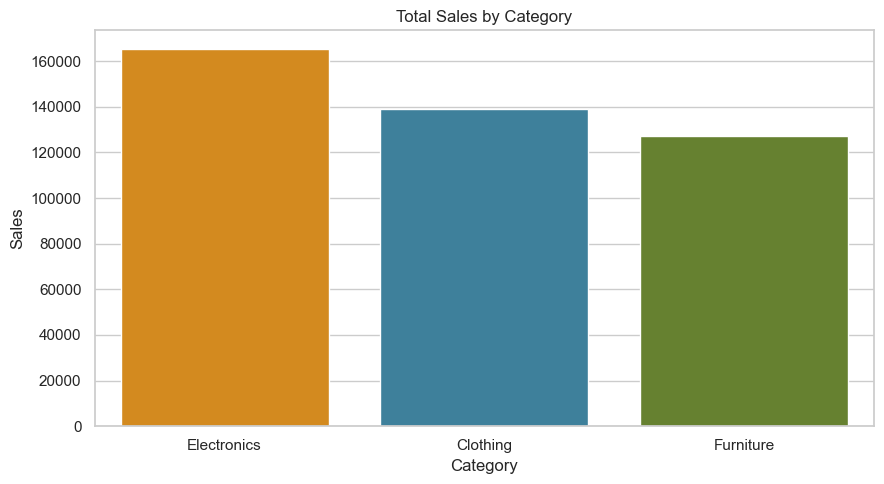

In [104]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales",
    hue="Category",
    palette=CATEGORY_COLORS,
    legend=False
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()

plt.savefig(
    "outputs/charts/category_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [105]:
print("Final dataset shape:", Sales.shape)

print("\nFinal dataset columns:")
print(Sales.columns.tolist())

print("\nOutput files:")
print(os.listdir("outputs"))

print("\nOutput tables:")
print(os.listdir("outputs/tables"))

print("\nOutput charts:")
print(os.listdir("outputs/charts"))

Final dataset shape: (1500, 19)

Final dataset columns:
['Order ID', 'Amount', 'Profit', 'Quantity', 'Category', 'Sub-Category', 'Order Date', 'CustomerName', 'State', 'City', 'Year', 'Month', 'Month_Number', 'Is_Loss', 'Year_Month', 'Original_State', 'State_Analysis', 'Half', 'Unit_Price']

Output files:
['charts', 'cleaned_sales_data.csv', 'tables']

Output tables:
['category_analysis.csv', 'category_extended.csv', 'city_analysis.csv', 'city_summary.csv', 'cleaning_log.csv', 'data_dictionary.csv', 'data_quality_report.csv', 'extended_kpis.csv', 'furniture_target_vs_actual.csv', 'half_year_summary.csv', 'key_findings.csv', 'loss_by_subcategory.csv', 'monthly_analysis.csv', 'monthly_analysis_year_month.csv', 'order_size_summary.csv', 'overall_kpis.csv', 'state_analysis.csv', 'state_summary.csv', 'subcategory_analysis.csv', 'target_comparison.csv', 'target_summary_by_category.csv', 'target_vs_actual_all_categories.csv', 'unit_price_summary.csv', 'validation_checks.csv', 'validation_repo